# Final parameter sweep for the poster: how common is bipartite signalling?

**What this notebook does.** It runs the poster's final α × β sweep: 9 × 9 points, 1,000 runs each, N = 10,000, signal
cost c = 0.001, mutation m0 = 0.01. It counts the **strict bipartite** runs at each point and draws the heatmap of their
prevalence. At the point with the most bipartite runs, it then re-runs up to 10 runs of every kind of bipartite
signalling, records the population every 25 steps, and plots how the strategies evolved.

**Names used on the poster** (the code still uses type numbers 0/1/2 and actions B/S/E):

| code | poster | share of population | payoff |
|---|---|---|---|
| type 0 (Umma in earlier notes) | **Bachites** | .33 + β | Bach 1 + α, Stravinsky 1, R&B .5 |
| type 1 (Kish) | **Stravinskians** | .33 − β | Stravinsky 1 + α, Bach 1, R&B .5 |
| type 2 (Akkadians) | **Millennials** | .34 | R&B 1, Bach 0, Stravinsky 0 |
| actions B / S / E | **Bach / Stravinsky / R&B** | | |
| signal 0 | **no signal** (silence: a silent agent reads every partner as silent) | | |

**Which code runs.** The simulations are the original model:
`FNs_genBachStravinsky_v0055k_assort_FLIP7_rep_execNULLsig_SMARTmutation.py`, unmodified. They are called through
`FNs_genBS_PSA_bipartite.py`, a copy whose lines 1–1554 are identical to the original. At its end, one block, marked
`PSA_poster additions`, adds a recording-only version of `genBSreplicatorexec_full_play`. It makes the same random-number
calls in the same order, so a seed gives a bit-identical trajectory (verified on 20 seeds). It additionally returns:
* the exact final counts of every strategy profile per type,
* a snapshot of those counts every `profile_record_interval` steps (400 in the sweep, 25 for the trajectory figures).

**Seeding.** Each grid point has one fixed entropy, listed below. Run r of a point uses child r of
`SeedSequence(entropy).spawn(1000)`, the same seeding as the original sweep notebook. Any run can therefore be
re-simulated exactly, and Part 1 ends with a check that it reproduces.

**Strict bipartite** (`bipartite` in the saved files) requires all three of the following:
1. one group ends split between two strategies that earn it different payoffs, and the smaller half holds ≥ 10% of the group;
2. the split held for the whole last 10,000 steps (25 snapshots, 400 steps apart);
3. the final state is a Nash equilibrium up to one agent of imbalance: no agent can gain more than 0.001 per
   interaction by switching strategy (ε-Nash).

**Saved data.** Everything goes to `results/final_sweep/`:
* one `.npz` per grid point, with final counts, snapshots of every run, labels and the entropy;
* the trajectory re-runs, in `trajectories/`;
* the figures, in `figures/`.

Re-running this notebook skips every point whose file already exists, so it rebuilds the figures from the saved data
without re-simulating. Delete a point's file to simulate it again.


In [1]:
import json, os, time
import numpy as np
import psa_bipartite_tools as T      # make_params, screen_point, run_batch, detectors (see that file)
import exploration_log as X          # CURRENT_/PAST_ progress report (project convention)

ALPHAS = [0.2, 0.22, 0.24, 0.26, 0.28, 0.3, 0.32, 0.34, 0.36]      # extra payoff for coordinating on one's favourite action
BETAS  = [0.04, 0.06, 0.08, 0.1, 0.12, 0.14, 0.16, 0.18, 0.2]      # Bachites' share = .33 + beta, Stravinskians' share = .33 - beta
RUNS = 1000                # runs per grid point
N = 10_000                 # population size
SIGNAL_COST = 0.001        # cost of sending signal 1 or 2 (signal 0 = no signal is free)
M0, M1 = 0.01, 0.1         # smart-mutation rates (the original notebook's mutation_rate = [m0, m1])
THRDS = 20                 # worker processes
OUT = 'results/final_sweep'
os.makedirs(OUT, exist_ok=True)

def point_path(a, b):
    return f'{OUT}/N{N}_a{a:.2f}_b{b:.2f}_runs{RUNS}_c{SIGNAL_COST:g}.npz'


## The entropy of every grid point

Drawn once with `numpy.random.SeedSequence().entropy` on 2026-11-17 and fixed here (also stored in
`results/final_sweep/entropy.json` and inside each point's `.npz` as `entropy`). Run r of point (α, β) is seeded with
`SeedSequence(ENTROPY[(α, β)]).spawn(1000)[r]`.

In [2]:
ENTROPY = {
    (0.20, 0.04): 63838938619458662269060203911485891470,
    (0.20, 0.06): 88682263804492338077454069413764487532,
    (0.20, 0.08): 255560052541513847875600322630100851216,
    (0.20, 0.10): 188053716349858984277864274824150838569,
    (0.20, 0.12): 301598978155857762383161064645053661898,
    (0.20, 0.14): 315077307666291451929813948414898601346,
    (0.20, 0.16): 45310544548305822744489507556766910074,
    (0.20, 0.18): 316389840696171972525962278995319017723,
    (0.20, 0.20): 133072975754856970744825622024716784755,
    (0.22, 0.04): 207031688341376282769052131228447320260,
    (0.22, 0.06): 121683969873637379562030187907281926572,
    (0.22, 0.08): 147247714874978525268922418616399146095,
    (0.22, 0.10): 138317057157324340405228676217534272300,
    (0.22, 0.12): 16441950269715507684910163491286266374,
    (0.22, 0.14): 210086938775976144507035678533788674800,
    (0.22, 0.16): 155676465732679995133192199160390697976,
    (0.22, 0.18): 200065995113993049443449279834366807725,
    (0.22, 0.20): 283156224368535227359303199546382305369,
    (0.24, 0.04): 168893461462487867901666885756304370130,
    (0.24, 0.06): 194587697553853609189491200697604142528,
    (0.24, 0.08): 281487699949459312061026275965775066030,
    (0.24, 0.10): 338987746241568800871303226437507267895,
    (0.24, 0.12): 106258061071794881317269732495674218059,
    (0.24, 0.14): 169413276708371496153996957764023620915,
    (0.24, 0.16): 328131507105421714918418404664172412725,
    (0.24, 0.18): 167456555336587130271532786573312141703,
    (0.24, 0.20): 299108511072535022375933195253439086484,
    (0.26, 0.04): 92250657647298279837840907302391634643,
    (0.26, 0.06): 245402859200046656069151702760409585048,
    (0.26, 0.08): 244079118987252166291682869759006083180,
    (0.26, 0.10): 335716918779125474017849314311488266334,
    (0.26, 0.12): 58059575357302027287236358589295109634,
    (0.26, 0.14): 264152276657349067087298744307117190945,
    (0.26, 0.16): 116466463886715404194788796896557886591,
    (0.26, 0.18): 142982087293828086842760905390810253408,
    (0.26, 0.20): 235085413713447798233017411414711625644,
    (0.28, 0.04): 313579994199998661398559463959170511511,
    (0.28, 0.06): 183042308469744433134942117742484808715,
    (0.28, 0.08): 259616005763867270470064234117957996254,
    (0.28, 0.10): 140137931354016238810538172909430001321,
    (0.28, 0.12): 272096469032414471252659178093006491210,
    (0.28, 0.14): 191802169857114274030358910023917666463,
    (0.28, 0.16): 153176444301636314246604886182644364008,
    (0.28, 0.18): 282391016408036277578954154218801208210,
    (0.28, 0.20): 11395515302388742693248519826427884722,
    (0.30, 0.04): 80700910414307621818348338393575295980,
    (0.30, 0.06): 74988950361379417800877704742807042602,
    (0.30, 0.08): 53797437614962684977214208845890410990,
    (0.30, 0.10): 209251892399205747865898754502676253975,
    (0.30, 0.12): 328864406873562150472989911165774464867,
    (0.30, 0.14): 94056425647365015640858045788857846586,
    (0.30, 0.16): 147928599003677178557609822996186512559,
    (0.30, 0.18): 263505140740157871941120358619494560119,
    (0.30, 0.20): 99817024681198229165074686521849193055,
    (0.32, 0.04): 52984711772797475010190383467281673646,
    (0.32, 0.06): 270137911294230057489832059167683767313,
    (0.32, 0.08): 99870250518353026945966279297412571042,
    (0.32, 0.10): 131899242998846721731047228854638542080,
    (0.32, 0.12): 40596763398405681980568385713665452608,
    (0.32, 0.14): 121363407755191379856526010486266788985,
    (0.32, 0.16): 316495724469037062532831885257210940978,
    (0.32, 0.18): 89913331141419290077036987553597410595,
    (0.32, 0.20): 7213482532487191684312052998307245654,
    (0.34, 0.04): 106717144425593614237117124757845415675,
    (0.34, 0.06): 276539122603747993118830095790694294239,
    (0.34, 0.08): 75854429132014639559435537180873506745,
    (0.34, 0.10): 58549116080674597092909891133876798289,
    (0.34, 0.12): 122889344039036222699943644402956991880,
    (0.34, 0.14): 332651646005240610315233065275646127052,
    (0.34, 0.16): 307833617073936683956472412673221710546,
    (0.34, 0.18): 97766835332162612017112506843388948910,
    (0.34, 0.20): 161895540020099923940545660122283639631,
    (0.36, 0.04): 320116803180579960132622243900804560450,
    (0.36, 0.06): 45838725377040037096761073470114457533,
    (0.36, 0.08): 10297241917281485704896704230659861835,
    (0.36, 0.10): 323391609700699013345229153828824416919,
    (0.36, 0.12): 304006647677277741786982901207854522570,
    (0.36, 0.14): 117043791600690006716359014054639269640,
    (0.36, 0.16): 114774057511101198674819706686439708335,
    (0.36, 0.18): 197538470075808058365411361774246830600,
    (0.36, 0.20): 105280328559430507820808633643334460793,
}

assert len(ENTROPY) == len(ALPHAS) * len(BETAS)
assert {k: str(v) for k, v in zip([f'{a:.2f},{b:.2f}' for a, b in ENTROPY], ENTROPY.values())} == json.load(open(f'{OUT}/entropy.json'))['entropy']
print('81 fixed entropies, one per grid point; e.g. (0.28, 0.12) ->', ENTROPY[(0.28, 0.12)])

81 fixed entropies, one per grid point; e.g. (0.28, 0.12) -> 272096469032414471252659178093006491210


## Part 1 — the sweep

For each grid point, `T.screen_point` does the following:
1. builds the original notebook's parameters with `T.make_params`;
2. runs the 1,000 seeded simulations in parallel (`T.run_batch`, 20 processes);
3. tests every run for a split, its stability and ε-Nash;
4. saves everything to the point's `.npz`.

Points whose file already exists are skipped. The table at the end is read from the saved files. A progress report
`CURRENT_exploration_<desc>.md` in the project folder is rewritten after every point; when the sweep finishes it is
archived to `archives/PAST_NN_...`.

In [3]:
timing_path = f'{OUT}/timing.json'
timing = json.load(open(timing_path)) if os.path.exists(timing_path) else {}
key = lambda a, b: f'N={N} α={a:.2f} β={b:.2f} runs={RUNS} c={SIGNAL_COST:g}'
todo = [(a, b) for a in ALPHAS for b in BETAS if not os.path.exists(point_path(a, b))]
print(f'{81 - len(todo)} of 81 points already saved; {len(todo)} to simulate')
if todo:
    E = X.Exploration(
        'a0.20-0.36_b0.04-0.20_c0.001_N10000_final_poster_sweep',
        'Final poster sweep: prevalence of strict bipartite signalling (9 x 9 grid, 1,000 runs per point)',
        'User request 2026-11-17: final heatmap for the poster. Centre = the best strict point so far at c = .001, '
        'N = 10,000, m0 = .01 (alpha .28, beta .12: 226/400); step .02 in both directions (user choice).',
        [f'grid: alpha {ALPHAS[0]:.2f}-{ALPHAS[-1]:.2f} x beta {BETAS[0]:.2f}-{BETAS[-1]:.2f}, step .02; {RUNS} runs/point; N {N:,}; '
         f'signal cost {SIGNAL_COST}; mutation m0 {M0}, m1 {M1}; T = 80,000 steps; null signal (original model)',
         'run from final_sweep.ipynb (fixed entropies listed in the notebook and in results/final_sweep/entropy.json)',
         f'results: {OUT}/ (one .npz per point)', f'threads: {THRDS}'],
        [(key(a, b), N * RUNS) for a in ALPHAS for b in BETAS],
        footer=['Re-run final_sweep.ipynb to resume (finished points are skipped).'])
    for a in ALPHAS:
        for b in BETAS:
            p = point_path(a, b)
            if os.path.exists(p):
                E.add(key(a, b), X.point_report(p), note='   (finished earlier)')
                continue
            t0 = time.perf_counter()
            s = T.screen_point(a, b, RUNS, p, population_size=N, thrds=THRDS, mutation_rate=(M0, M1),
                               signal_cost=-SIGNAL_COST, entropy=ENTROPY[(a, b)])
            m = (time.perf_counter() - t0) / 60
            timing[f'{a:.2f},{b:.2f}'] = m
            json.dump(timing, open(timing_path, 'w'), indent=1)
            E.add(key(a, b), X.point_report(p), minutes=m)
            print(f'alpha {a:.2f} beta {b:.2f}: strict bipartite {s["bipartite"]:4d} / {RUNS}   [{m:.1f} min]', flush=True)
    print('report archived to', E.finish())

# summary table read from the saved files
STRICT = np.full((len(ALPHAS), len(BETAS)), -1)
for i, a in enumerate(ALPHAS):
    for j, b in enumerate(BETAS):
        if os.path.exists(point_path(a, b)):
            d = np.load(point_path(a, b), allow_pickle=True)
            assert int(d['entropy'].item()) == ENTROPY[(a, b)] and int(d['runs']) == RUNS
            STRICT[i, j] = int(d['bipartite'].sum())
print('\nstrict bipartite runs per 1,000 (rows alpha, columns beta; -1 = not run yet)')
print('alpha\\beta ' + ' '.join(f'{b:6.2f}' for b in BETAS))
for i, a in enumerate(ALPHAS):
    print(f'{a:9.2f}  ' + ' '.join(f'{v:6d}' for v in STRICT[i]))
if timing:
    print(f'\nsimulation time: {sum(timing.values()) / 60:.1f} h for {len(timing)} points ({np.mean(list(timing.values())):.1f} min/point)')

81 of 81 points already saved; 0 to simulate

strict bipartite runs per 1,000 (rows alpha, columns beta; -1 = not run yet)
alpha\beta   0.04   0.06   0.08   0.10   0.12   0.14   0.16   0.18   0.20
     0.20      24     25     20     10      1      0      0      4    171
     0.22      18     30     14      7      1     10     21     19    172
     0.24      14     23     23     19     76    107     91     72    181
     0.26      35    100    333    503    462    351    236    180    238
     0.28      13     50    222    509    534    411    369    248    210
     0.30      10     12     75    311    549    443    378    282    222
     0.32       6     14     18    110    388    445    422    282    223
     0.34       4      6      9     28    176    422    425    285    227
     0.36       7      5      6      8     34    239    419    347    237

simulation time: 9.8 h for 81 points (7.3 min/point)


### Check: a saved run can be re-simulated exactly from its entropy

This re-runs runs 0 and 1 of the centre point (α .28, β .12) from the entropy above and compares the final counts
with the saved ones (it takes about a minute).

In [4]:
a, b = 0.28, 0.12
d = np.load(point_path(a, b), allow_pickle=True)
P = T.file_params(d)
B = T.run_batch(P, RUNS, entropy=ENTROPY[(a, b)], thrds=2, run_ids=[0, 1], keep_profile_time=False)
for i, r in enumerate([0, 1]):
    same = np.array_equal(B['final_counts'][i], d['final_counts'][r])
    print(f'run {r}: re-simulated final counts identical to the saved ones: {same}')
    assert same

run 0: re-simulated final counts identical to the saved ones: True
run 1: re-simulated final counts identical to the saved ones: True


## Part 2 — heatmap of strict bipartite signalling

The heatmap reads only the saved files: Part 1's `STRICT` table, which holds the strict bipartite runs per 1,000 at each
point. The figure is sized for the poster (fonts ≥ 24 pt when printed about 11 in wide). It is saved as PDF and PNG to
`results/final_sweep/figures/`.

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import split_anatomy as SA

FIG = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)
INK, INK2, SURFACE = '#0b0b0b', '#52514e', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']   # fixed categorical order
SEQ = LinearSegmentedColormap.from_list('blues', ['#f3f6fa', '#b9d3f0', '#5d9be0', '#2a78d6', '#123f78'])  # one hue, light -> dark

GROUP = ['Bachites', 'Stravinskians', 'Millennials']
ACTION = ['Bach', 'Stravinsky', 'R&B']
_RENAME = [('Umma-copy', 'Bachite-copy'), ('Kish-copy', 'Stravinskian-copy'), ('Umma', 'Bachites'), ('Kish', 'Stravinskians'),
           ('Akkad', 'Millennials'), ('blind', 'silent'), ('B-in', 'Bach-in'), ('S-in', 'Stravinsky-in'), ('E-in', 'R&B-in')]

def poster_name(label):
    '''Split label in poster names: 'Umma [blind | Kish-copy]' -> 'Bachites [silent | Stravinskian-copy]'.'''
    for old, new in _RENAME:
        label = label.replace(old, new)
    return label

def split_kind(d, r, M):
    '''Kind of bipartite signalling of run r: the split label (poster names), plus whose signal a copying half borrows
    when that signal is also the Millennials' own (the two variants of the Bachite split).'''
    lab = str(d['split_label'][r])
    t = ['Umma', 'Kish', 'Akkad'].index(lab.split()[0])
    a = SA.anatomy(d['final_counts'][r], t, M, lab)
    kind = poster_name(lab)
    lenders = [str(a['h1_lender']), str(a['h2_lender'])]
    if any('+' in l for l in lenders):
        kind += " (copy half on the Millennials' signal)"
    return kind

def behaviour(p):
    '''Payoff-relevant behaviour of profile p: a silent agent reads every partner as silent, so only its action toward
    silence matters; a signalling agent's three actions all matter.'''
    s, a0, a1, a2 = T.PROFILES[p]
    return ('silent', int(a0)) if s == 0 else (int(s), int(a0), int(a1), int(a2))

def behaviour_text(k):
    if k[0] == 'silent':
        return f'no signal; {ACTION[k[1]]} with everyone'
    s, a0, a1, a2 = k
    return f'shows signal {s}; ' + ', '.join(f'{w}→{ACTION[x]}' for w, x in zip(('silent', '1', '2'), (a0, a1, a2)))

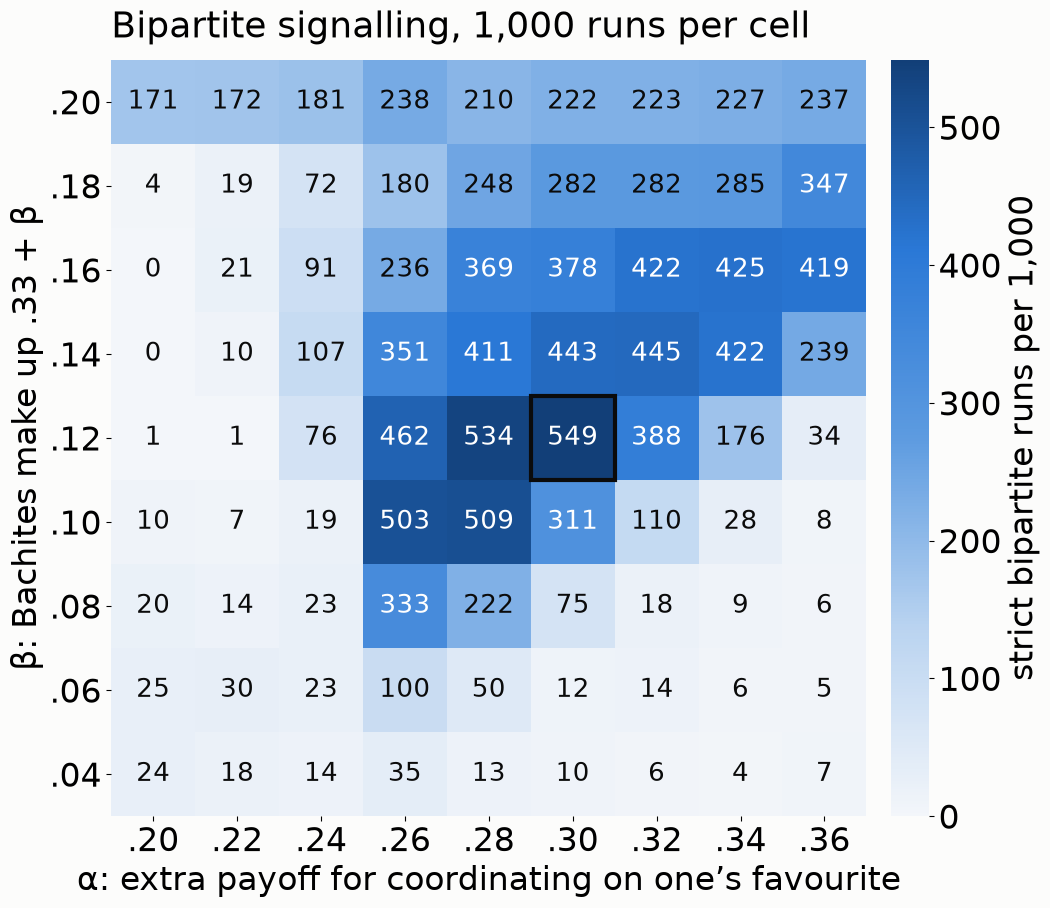

total strict bipartite runs on the grid: 13,231 of 81,000


In [6]:
def heatmap(Z, title, path, vmax=None, runs=RUNS, mark=True):
    plt.rcParams.update({'font.size': 24, 'font.family': 'DejaVu Sans'})
    fig, ax = plt.subplots(figsize=(11, 9.6), facecolor=SURFACE)
    Zm = np.ma.masked_less(Z.astype(float), 0)
    vmax = vmax or max(1, Zm.max())
    im = ax.imshow(Zm.T, origin='lower', cmap=SEQ, vmin=0, vmax=vmax, aspect='auto')
    for i in range(Z.shape[0]):
        for j in range(Z.shape[1]):
            if Z[i, j] >= 0:
                ax.text(i, j, f'{Z[i, j]}', ha='center', va='center', fontsize=19,
                        color='white' if Z[i, j] > .55 * vmax else INK)
    if mark and (Z >= 0).any():
        bi, bj = np.unravel_index(np.argmax(Z), Z.shape)
        ax.add_patch(plt.Rectangle((bi - .5, bj - .5), 1, 1, fill=False, ec=INK, lw=3))
    ax.set_xticks(range(len(ALPHAS)), [f'{a:.2f}'[1:] for a in ALPHAS])
    ax.set_yticks(range(len(BETAS)), [f'{b:.2f}'[1:] for b in BETAS])
    ax.set_xlabel('α: extra payoff for coordinating on one’s favourite')
    ax.set_ylabel('β: Bachites make up .33 + β')
    cb = fig.colorbar(im, ax=ax, fraction=.05, pad=.03)
    cb.set_label(f'strict bipartite runs per {runs:,}')
    cb.outline.set_visible(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, loc='left', fontsize=26, pad=16)
    fig.tight_layout()
    for ext in ('pdf', 'png'):
        fig.savefig(f'{path}.{ext}', dpi=200, facecolor=SURFACE)
    plt.show()

heatmap(STRICT, f'Bipartite signalling, {RUNS:,} runs per cell', f'{FIG}/heatmap_strict_bipartite')
print(f'total strict bipartite runs on the grid: {STRICT[STRICT >= 0].sum():,} of {RUNS * (STRICT >= 0).sum():,}')

### Which kinds of bipartite signalling, and where

Every strict bipartite run gets a kind, from its split label in poster names: `<split group> [<half> | <half>]`. The
half codes are:
* `silent`: the half shows no signal;
* `X-copy`: the half shows group X's signal and copies its strategy;
* `Y-in`: the half coordinates within itself on Y.

The Bachite split has two variants that differ in whose signal the copying half borrows: the Stravinskians' own, or a
signal the Stravinskians share with the Millennials. The variant is added to the kind.

strict bipartite runs on the whole grid, by kind:
  12,228  Bachites [silent | Stravinskian-copy]
     533  Bachites [silent | Stravinskian-copy] (copy half on the Millennials' signal)
     425  Stravinskians [Bach-in | Bach-in]
      25  Bachites [Stravinsky-in | Stravinskian-copy]
      10  Stravinskians [R&B-in | Bach-in]
       7  Stravinskians [R&B-in | Stravinsky-in]
       2  Stravinskians [R&B-in | Bachite-copy]
       1  Bachites [R&B-in | Stravinskian-copy]


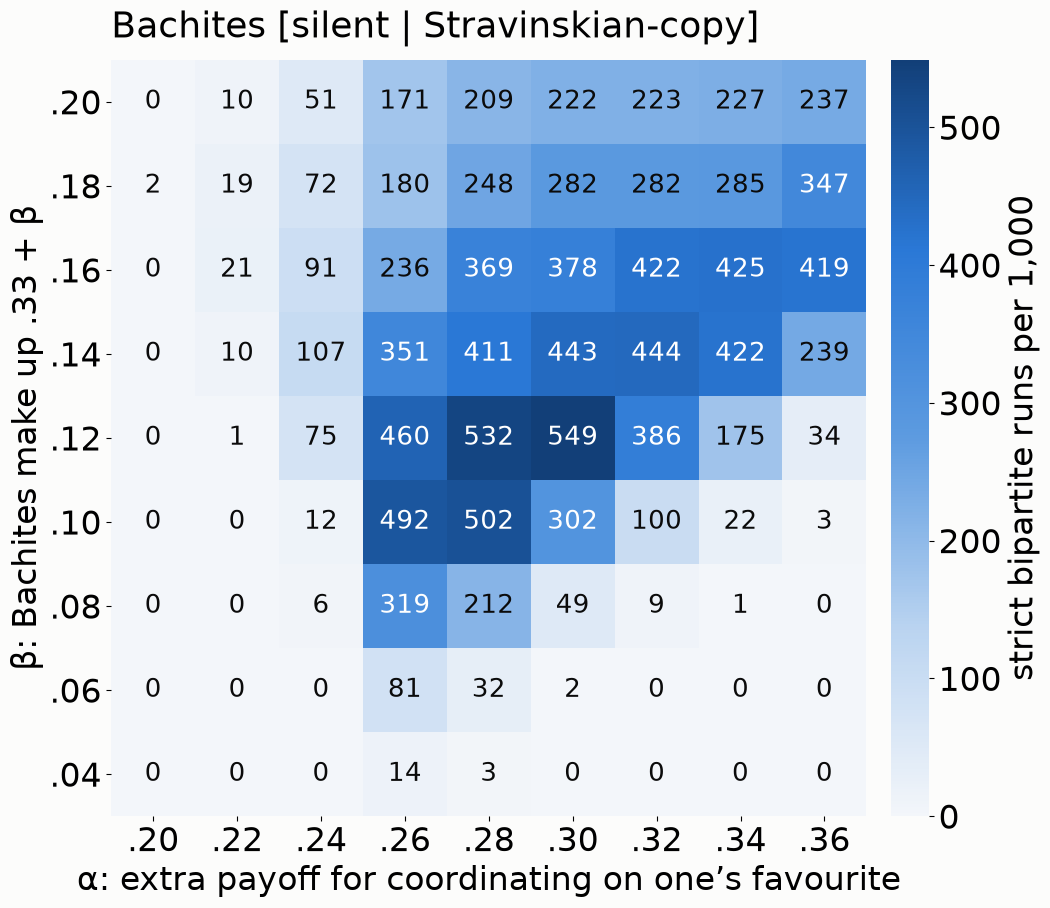

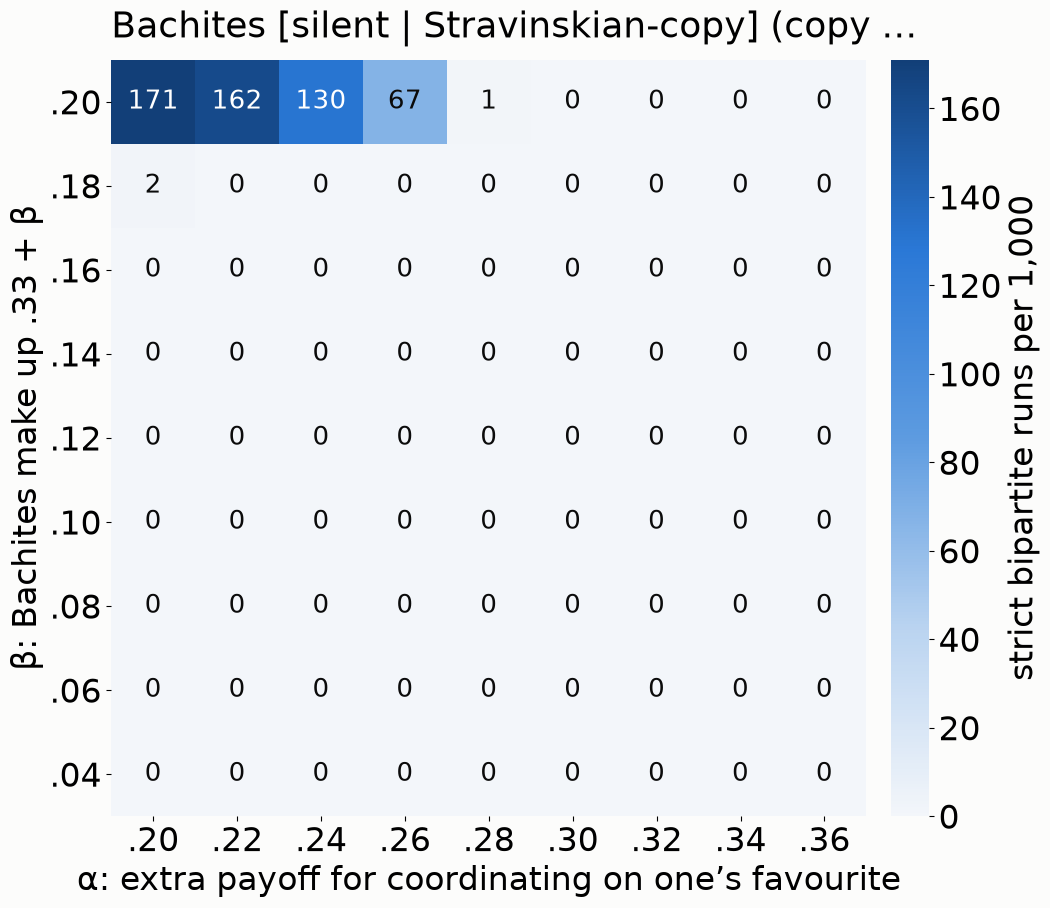

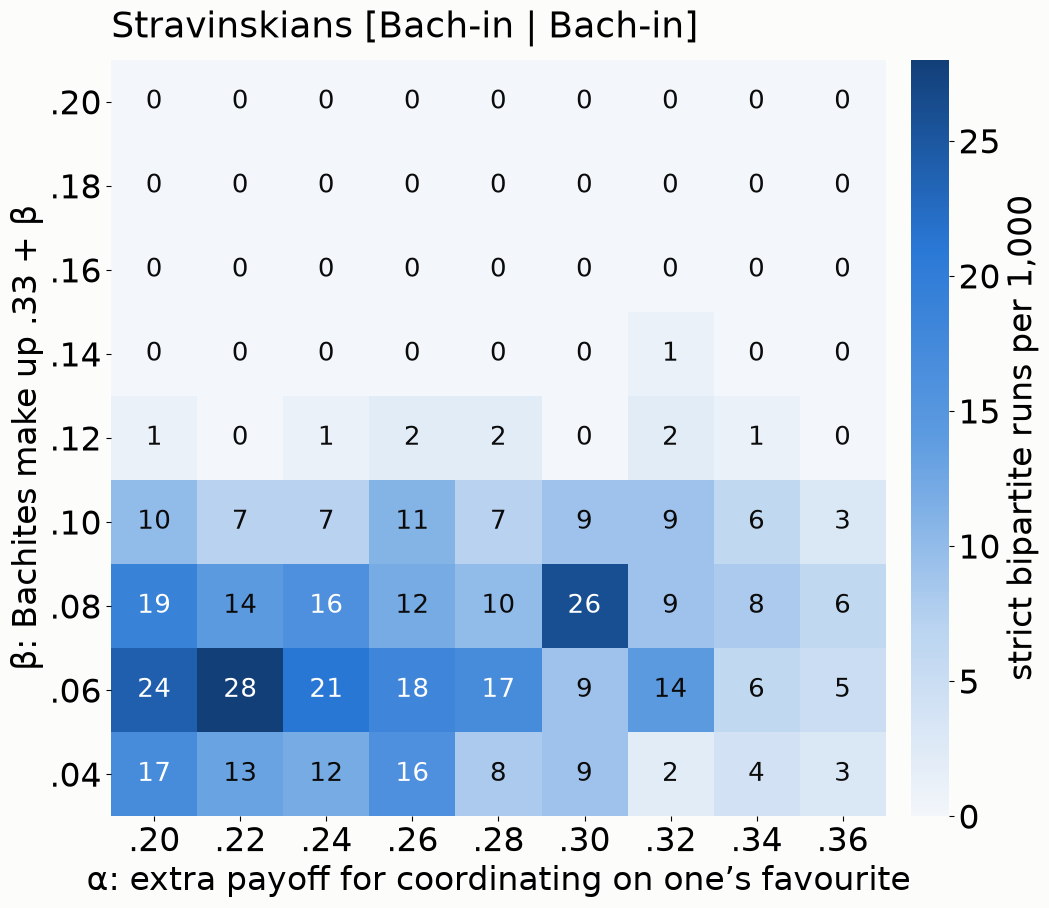

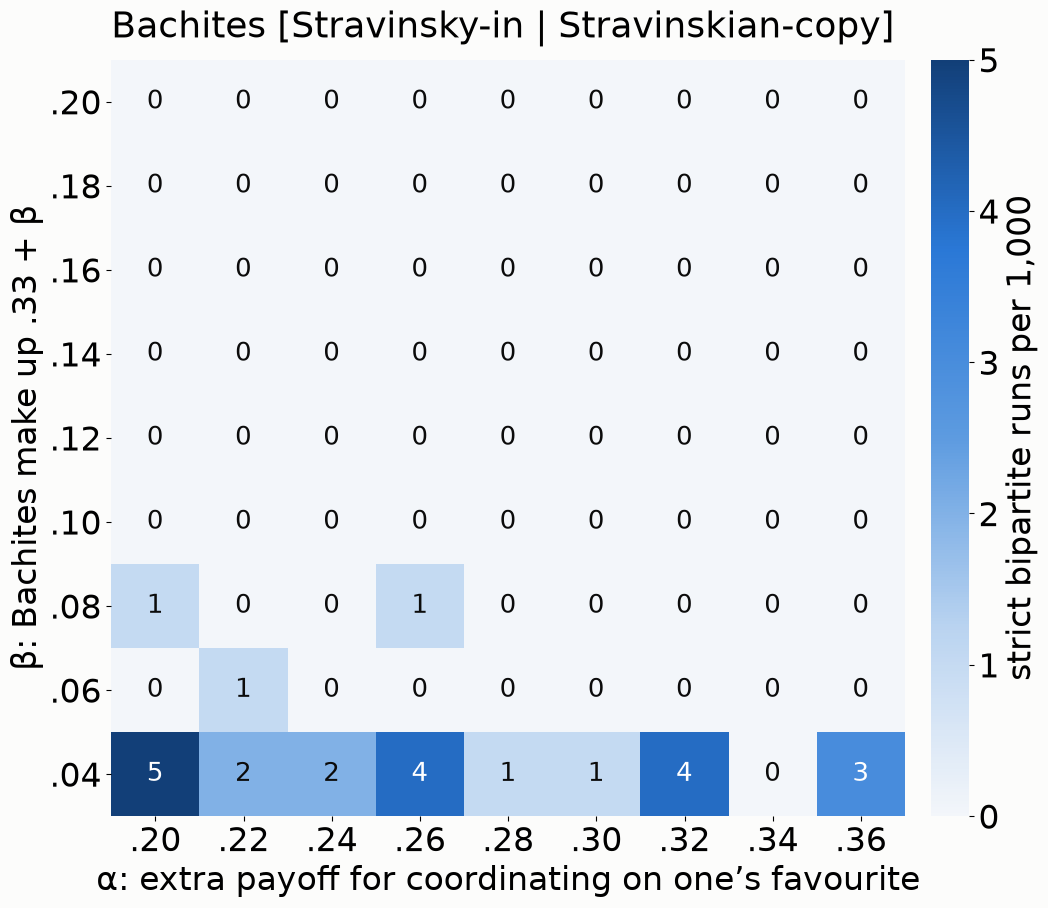

In [7]:
M_ = {}
KIND = {}      # (alpha, beta) -> {run: kind}
for i, a in enumerate(ALPHAS):
    for j, b in enumerate(BETAS):
        if STRICT[i, j] <= 0:
            continue
        d = np.load(point_path(a, b), allow_pickle=True)
        M = T.point_matrix(d)
        KIND[(a, b)] = {int(r): split_kind(d, r, M) for r in np.flatnonzero(d['bipartite'])}
import collections
tot = collections.Counter(k for v in KIND.values() for k in v.values())
print('strict bipartite runs on the whole grid, by kind:')
for k, n in tot.most_common():
    print(f'  {n:6,}  {k}')
kinds_big = [k for k, n in tot.most_common() if n >= 20][:4]
for k in kinds_big:
    Z = np.array([[sum(1 for v in KIND.get((a, b), {}).values() if v == k) if STRICT[i, j] >= 0 else -1
                   for j, b in enumerate(BETAS)] for i, a in enumerate(ALPHAS)])
    fn = k.split(' (')[0].replace(' ', '_').replace('[', '').replace(']', '').replace('|', '').replace('&', 'and').replace('__', '_')
    heatmap(Z, k if len(k) < 46 else k[:44] + '…', f'{FIG}/heatmap_kind_{fn}' + ('_millennial_signal' if '(' in k else ''), mark=False)

## Part 3 — how the strategies evolved, at the point with the most bipartite signalling

At the point with the most strict bipartite runs, the notebook picks up to 10 runs of each kind; if a kind has fewer
than 10, it takes all of them. The pick is random, with the fixed seed below, so it is reproducible. Each picked run is
re-simulated exactly from its entropy, with the population recorded every 25 steps. `T.rerun_fine` checks that the
re-run ends in exactly the saved final state. The re-runs are cached in `results/final_sweep/trajectories/`, so
re-running this notebook only redraws them.

**How to read a figure.** Each row is one group. The coloured bands are the shares of the group using each behaviour.
For a silent agent only its action toward silence matters; for a signalling agent all three actions matter. The eight
behaviours that ever reach the largest shares get colours, and the same behaviour has the same colour in every row, so
copying shows up as one colour in two rows. Everything else is grey. Time runs on a log scale from step 25 to 80,000,
because most of the action happens in the first few hundred steps.

**Why the halves move.** The balance between the two halves depends on the Millennials. The more Millennials play
Bach with silent partners (in the Bachite split, the band "silent→Bach" in the Millennials row), the less the signal is
worth to a Bachite and the smaller the signalling half. That share drifts up slowly and then crashes, so the halves move
in a sawtooth around a moving balance point.

**Spikes.** Sharp one-snapshot drops of a half, followed by regrowth, are *replicator overshoot*. In a single step one
half can lose most of its members, then it re-invades from mutants within about 15 steps; the split's balance point
does not move. The 25-step snapshots catch many of these dips. The 400-step snapshots behind the strict criterion
rarely do: a run counts as strict only if none of its last 25 snapshots (400 steps apart) caught one.

In [8]:
SELECT_SEED = 20261117          # fixed seed for picking the runs
PER_KIND = 10
ib = np.unravel_index(np.argmax(STRICT), STRICT.shape)
A_BEST, B_BEST = ALPHAS[ib[0]], BETAS[ib[1]]
BEST_PATH = point_path(A_BEST, B_BEST)
print(f'most strict bipartite runs: alpha {A_BEST:.2f}, beta {B_BEST:.2f} ({STRICT[ib]} of {RUNS})')
kinds_here = KIND[(A_BEST, B_BEST)]
rng = np.random.default_rng(SELECT_SEED)
CHOSEN = {}
for k, n in collections.Counter(kinds_here.values()).most_common():
    runs_k = sorted(r for r, kk in kinds_here.items() if kk == k)
    CHOSEN[k] = runs_k if len(runs_k) <= PER_KIND else sorted(int(x) for x in rng.choice(runs_k, PER_KIND, replace=False))
    print(f'{n:4d} runs  {k}\n      chosen: {CHOSEN[k]}')
json.dump(dict(alpha=A_BEST, beta=B_BEST, seed=SELECT_SEED, chosen=CHOSEN), open(f'{OUT}/trajectory_selection.json', 'w'), indent=1)

most strict bipartite runs: alpha 0.30, beta 0.12 (549 of 1000)
 549 runs  Bachites [silent | Stravinskian-copy]
      chosen: [151, 213, 243, 673, 704, 721, 791, 806, 842, 963]


In [9]:
TRAJ = f'{OUT}/trajectories'
ids = sorted({r for v in CHOSEN.values() for r in v})
t0 = time.perf_counter()
FINE = T.rerun_fine(BEST_PATH, ids, interval=25, thrds=THRDS, cache_dir=TRAJ)   # cached; raises if a re-run differs
print(f'{len(FINE)} runs with snapshots every 25 steps ({(time.perf_counter() - t0) / 60:.1f} min; cached in {TRAJ}/)')

10 runs with snapshots every 25 steps (0.3 min; cached in results/final_sweep/trajectories/)


In [10]:
TFIG = f'{TRAJ}/figs'
os.makedirs(TFIG, exist_ok=True)
dbest = np.load(BEST_PATH, allow_pickle=True)
T.point_matrix(dbest)
BEH = [behaviour(p) for p in range(T.NUMPROFILES)]
KEYS = sorted(set(BEH), key=str)

def behaviour_shares(pt):
    '''pt: (3, 81, K) counts -> {key: (3, K) shares of each group}.'''
    tot = pt.sum(1, keepdims=True).astype(float)
    out = {k: np.zeros((3, pt.shape[2])) for k in KEYS}
    for p, k in enumerate(BEH):
        out[k] += pt[:, p, :] / tot[:, 0, :]
    return out

def plot_run(r, kind):
    f = FINE[r]
    pt = f['profile_time']
    steps = 25 * (np.arange(pt.shape[2]) + 1)
    sh = behaviour_shares(pt)
    top = sorted(KEYS, key=lambda k: -sh[k].max())[:8]
    col = {k: SERIES[i] for i, k in enumerate(top)}
    plt.rcParams.update({'font.size': 13, 'font.family': 'DejaVu Sans'})
    fig, axs = plt.subplots(3, 1, figsize=(13, 11), sharex=True, facecolor=SURFACE)
    for t, ax in enumerate(axs):
        layers = [sh[k][t] for k in top] + [1 - sum(sh[k][t] for k in top)]
        ax.stackplot(steps, layers, colors=[col[k] for k in top] + ['#d6d5d0'], edgecolor=SURFACE, linewidth=.4)
        ax.set_xscale('log')
        ax.set_xlim(25, steps[-1])
        ax.set_ylim(0, 1)
        ax.set_ylabel(f'{GROUP[t]}\nshare', fontsize=13)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
    axs[-1].set_xlabel('step (log scale)')
    handles = [plt.Rectangle((0, 0), 1, 1, color=col[k]) for k in top] + [plt.Rectangle((0, 0), 1, 1, color='#d6d5d0')]
    fig.legend(handles, [behaviour_text(k) for k in top] + ['all other behaviours'], loc='lower center',
               bbox_to_anchor=(.5, 0), ncol=2, frameon=False, fontsize=11.5)
    fig.suptitle(f'run {r} at α {A_BEST:.2f}, β {B_BEST:.2f}: {kind}', x=.02, ha='left', fontsize=15)
    fig.tight_layout(rect=(0, .17, 1, .97))
    fn = f'{TFIG}/run{r:04d}.png'
    fig.savefig(fn, dpi=130, facecolor=SURFACE)
    plt.close(fig)
    return fn

for k, rs in CHOSEN.items():
    files = [plot_run(r, k) for r in rs]
    print(f'{k}: {len(files)} figures, e.g. {files[0]}')

Bachites [silent | Stravinskian-copy]: 10 figures, e.g. results/final_sweep/trajectories/figs/run0151.png


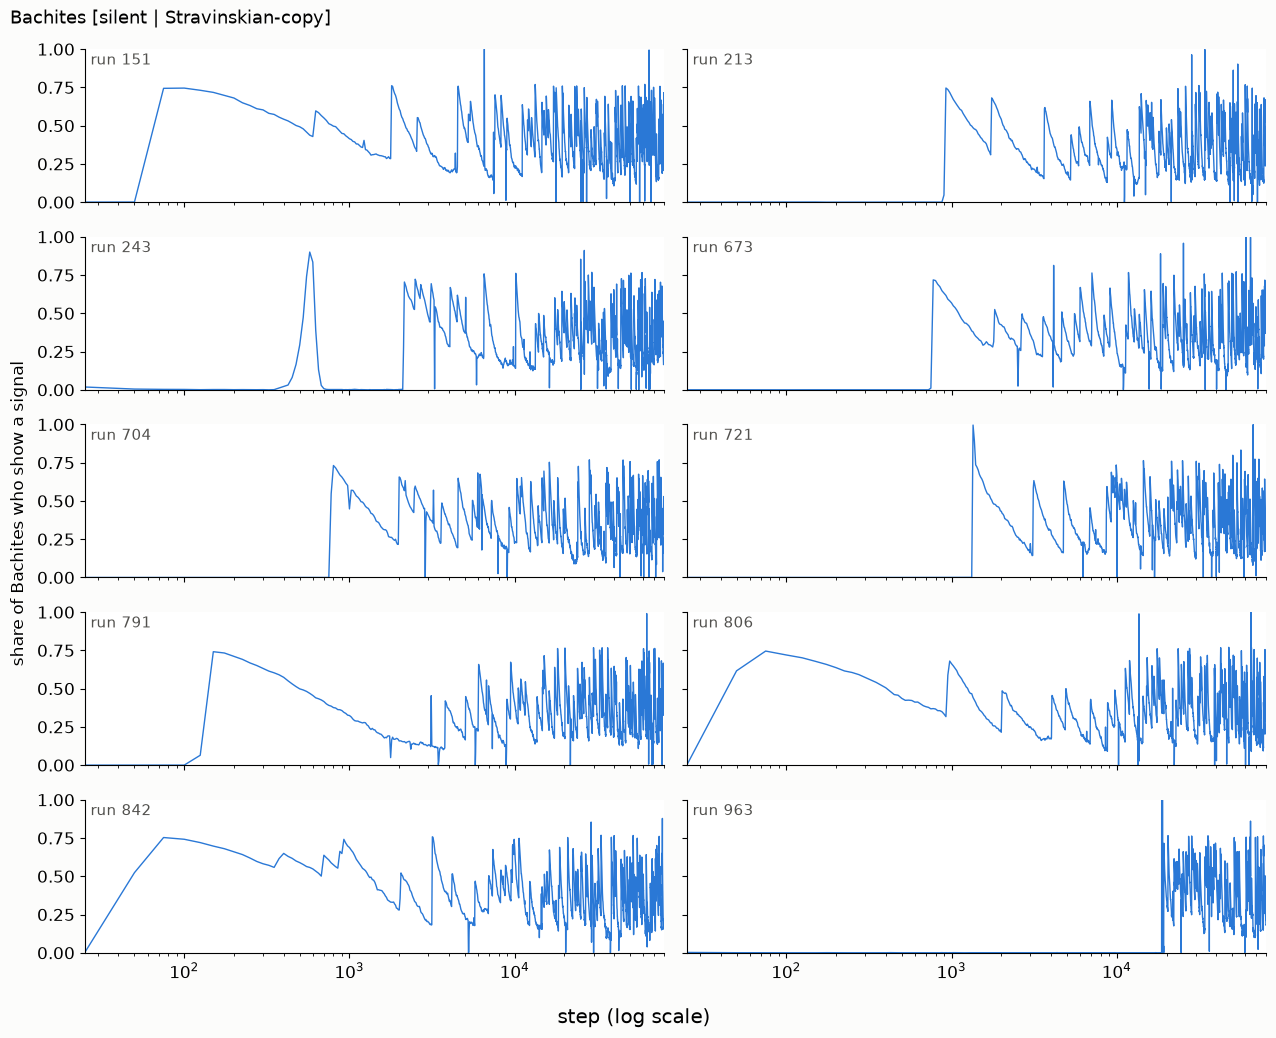

In [11]:
# overview: one small panel per chosen run, the share of the split group in its signalling (or smaller) half over time
plt.rcParams.update({'font.size': 12})
sig = T.PROFILES[:, 0]
for k, rs in CHOSEN.items():
    t = GROUP.index(k.split()[0])
    nrow = int(np.ceil(len(rs) / 2))
    fig, axs = plt.subplots(nrow, 2, figsize=(13, 1.9 * nrow + 1), sharex=True, sharey=True, facecolor=SURFACE, squeeze=False)
    for ax, r in zip(axs.flat, rs):
        pt = FINE[r]['profile_time']
        steps = 25 * (np.arange(pt.shape[2]) + 1)
        fin = FINE[r]['final_counts'][t]
        if 'silent' in k:     # one half is silent: plot the signalling half (everyone of the group who shows a signal)
            on = sig != 0
        else:                 # otherwise: the smaller half's signal in the final state
            halves = np.array([fin[sig == s].sum() for s in range(T.NUMSIGNALS)])
            order = np.argsort(halves)[::-1]
            on = sig == (order[1] if halves[order[1]] > 0 else order[0])
        ax.plot(steps, pt[t][on].sum(0) / pt[t].sum(0), color=SERIES[0], lw=1)
        ax.set_xscale('log'); ax.set_xlim(25, 80000); ax.set_ylim(0, 1)
        ax.text(.01, .9, f'run {r}', transform=ax.transAxes, fontsize=11, color=INK2)
        for s_ in ('top', 'right'):
            ax.spines[s_].set_visible(False)
    for ax in axs.flat[len(rs):]:
        ax.set_visible(False)
    fig.supxlabel('step (log scale)')
    fig.supylabel(f'share of {GROUP[t]} ' + ('who show a signal' if 'silent' in k else 'on the smaller half’s signal'), fontsize=12)
    fig.suptitle(k, x=.02, ha='left', fontsize=13)
    fig.tight_layout()
    fn = k.split(' (')[0].replace(' ', '_').replace('[', '').replace(']', '').replace('|', '').replace('&', 'and').replace('__', '_')
    fig.savefig(f'{TFIG}/overview_{fn}' + ('_millennial_signal' if '(' in k else '') + '.png', dpi=130, facecolor=SURFACE)
    plt.show()

Bachites [silent | Stravinskian-copy]


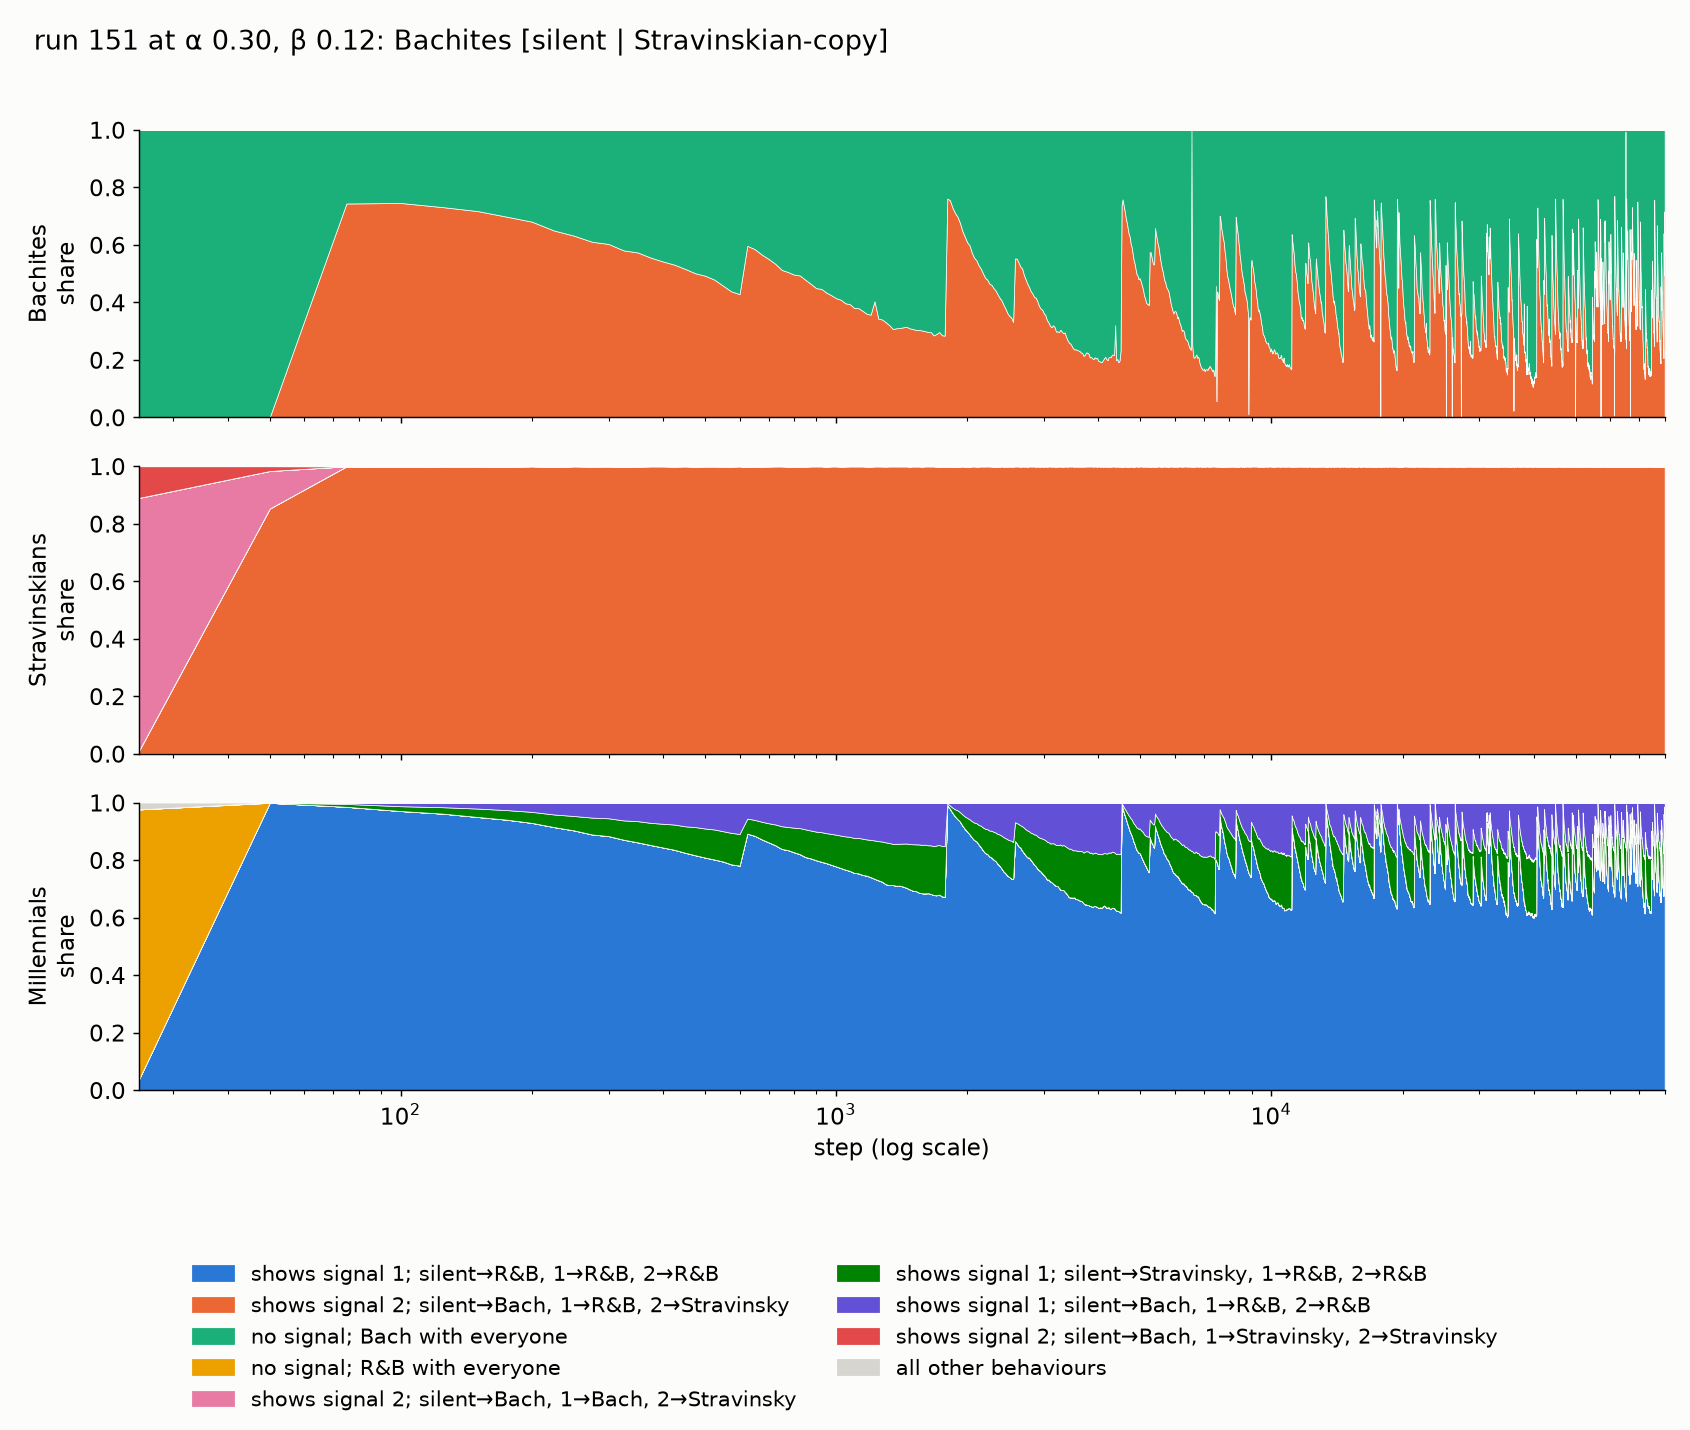

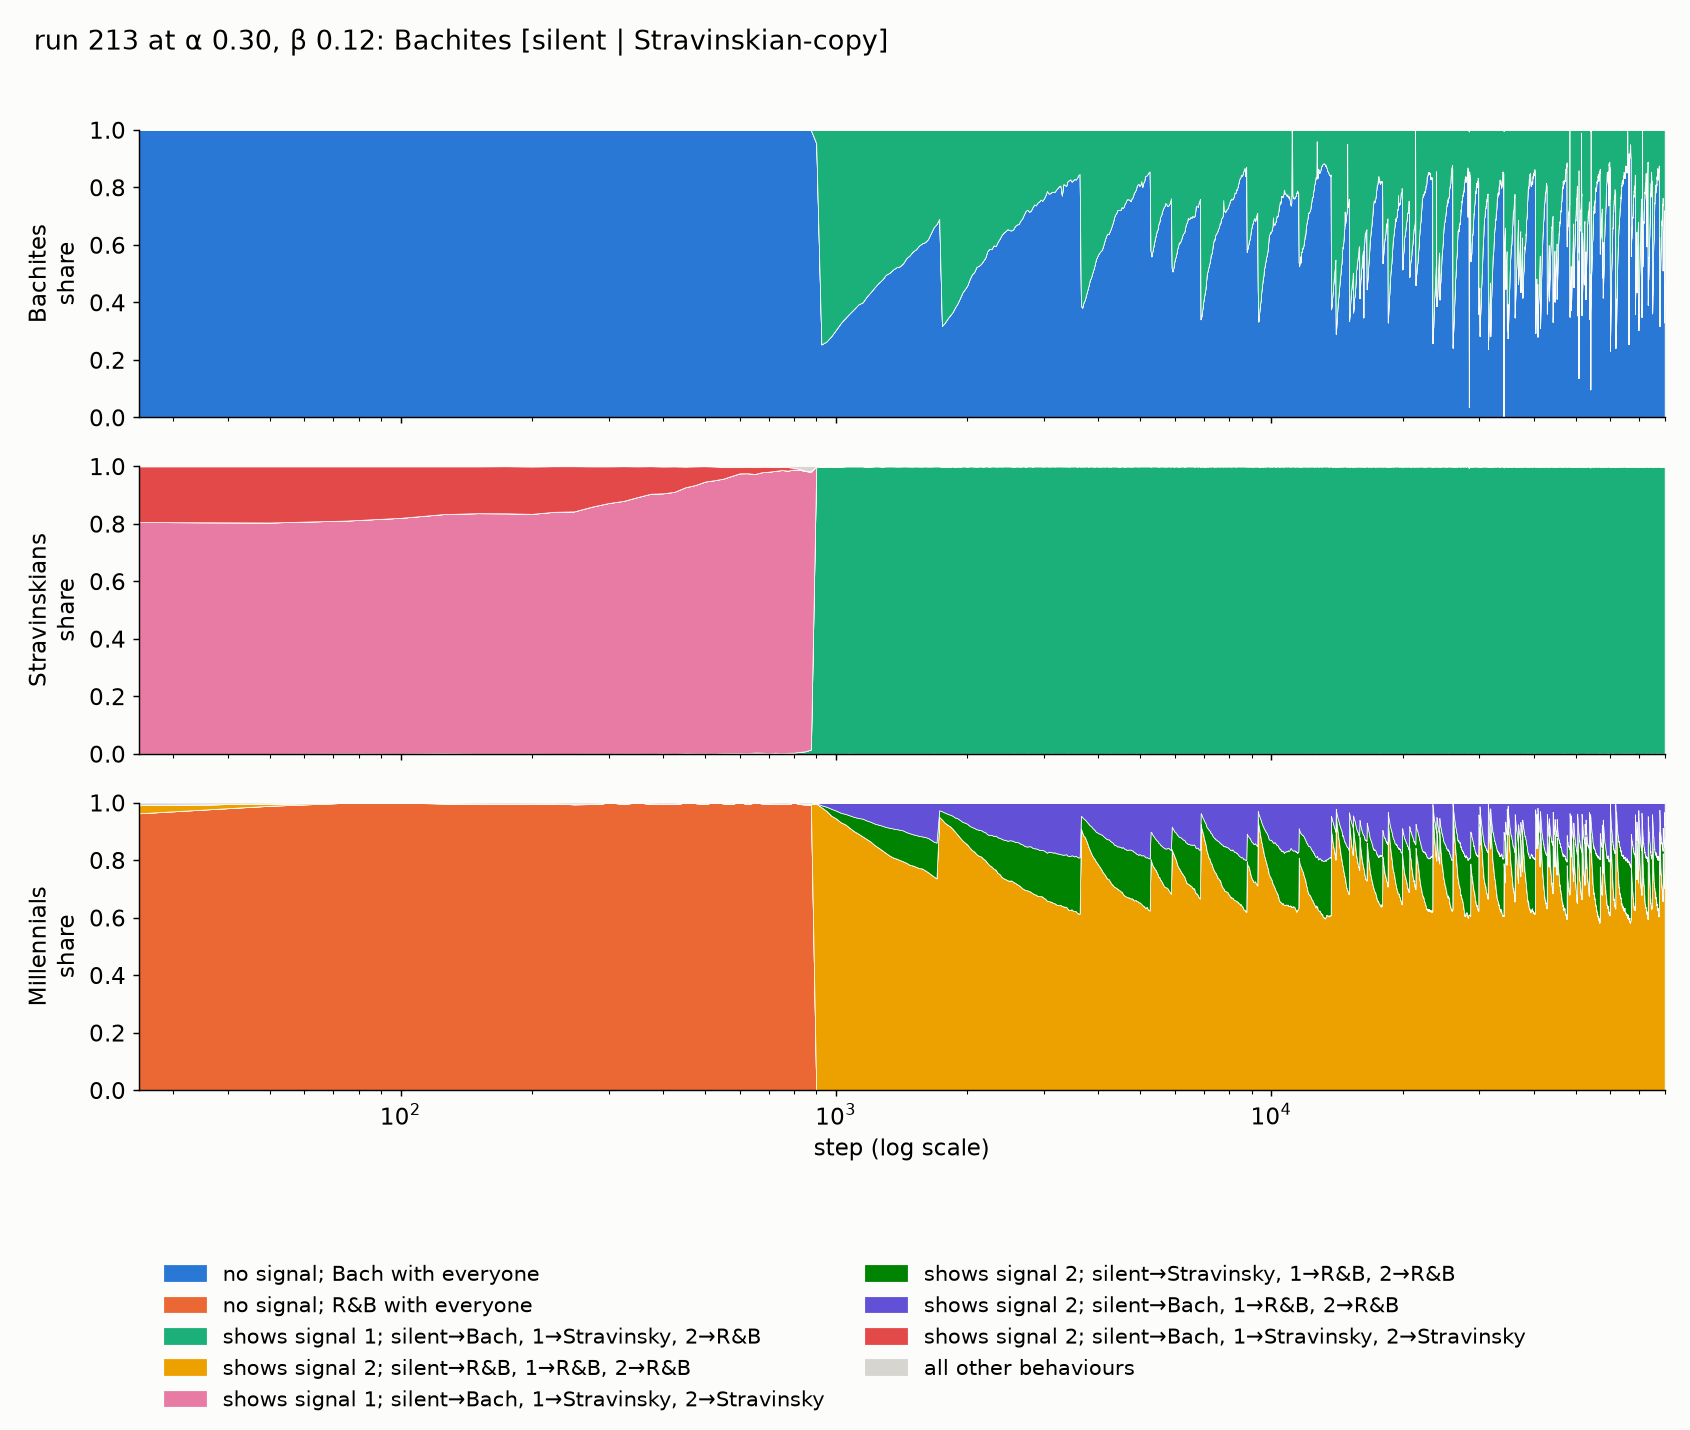

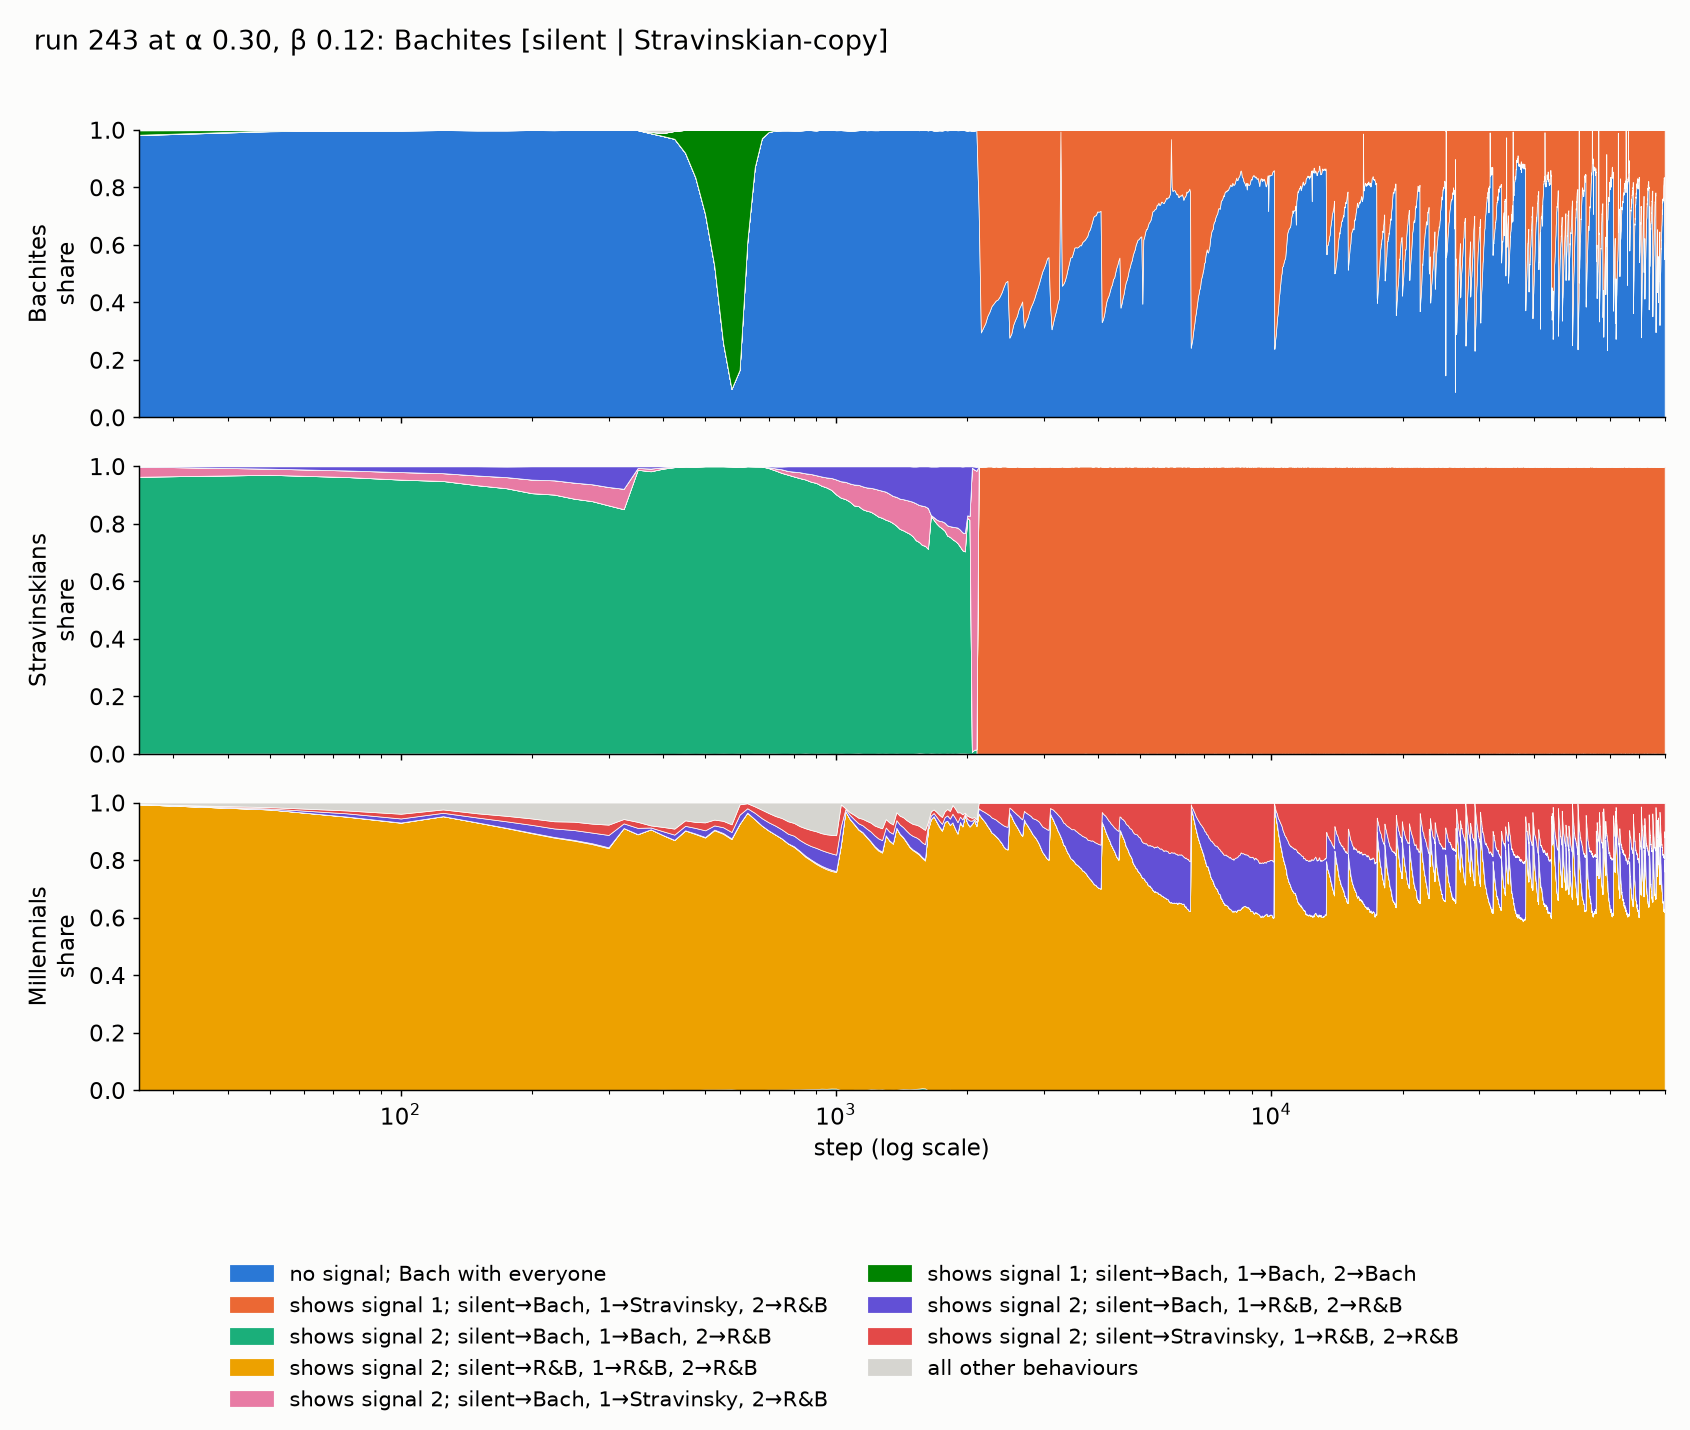

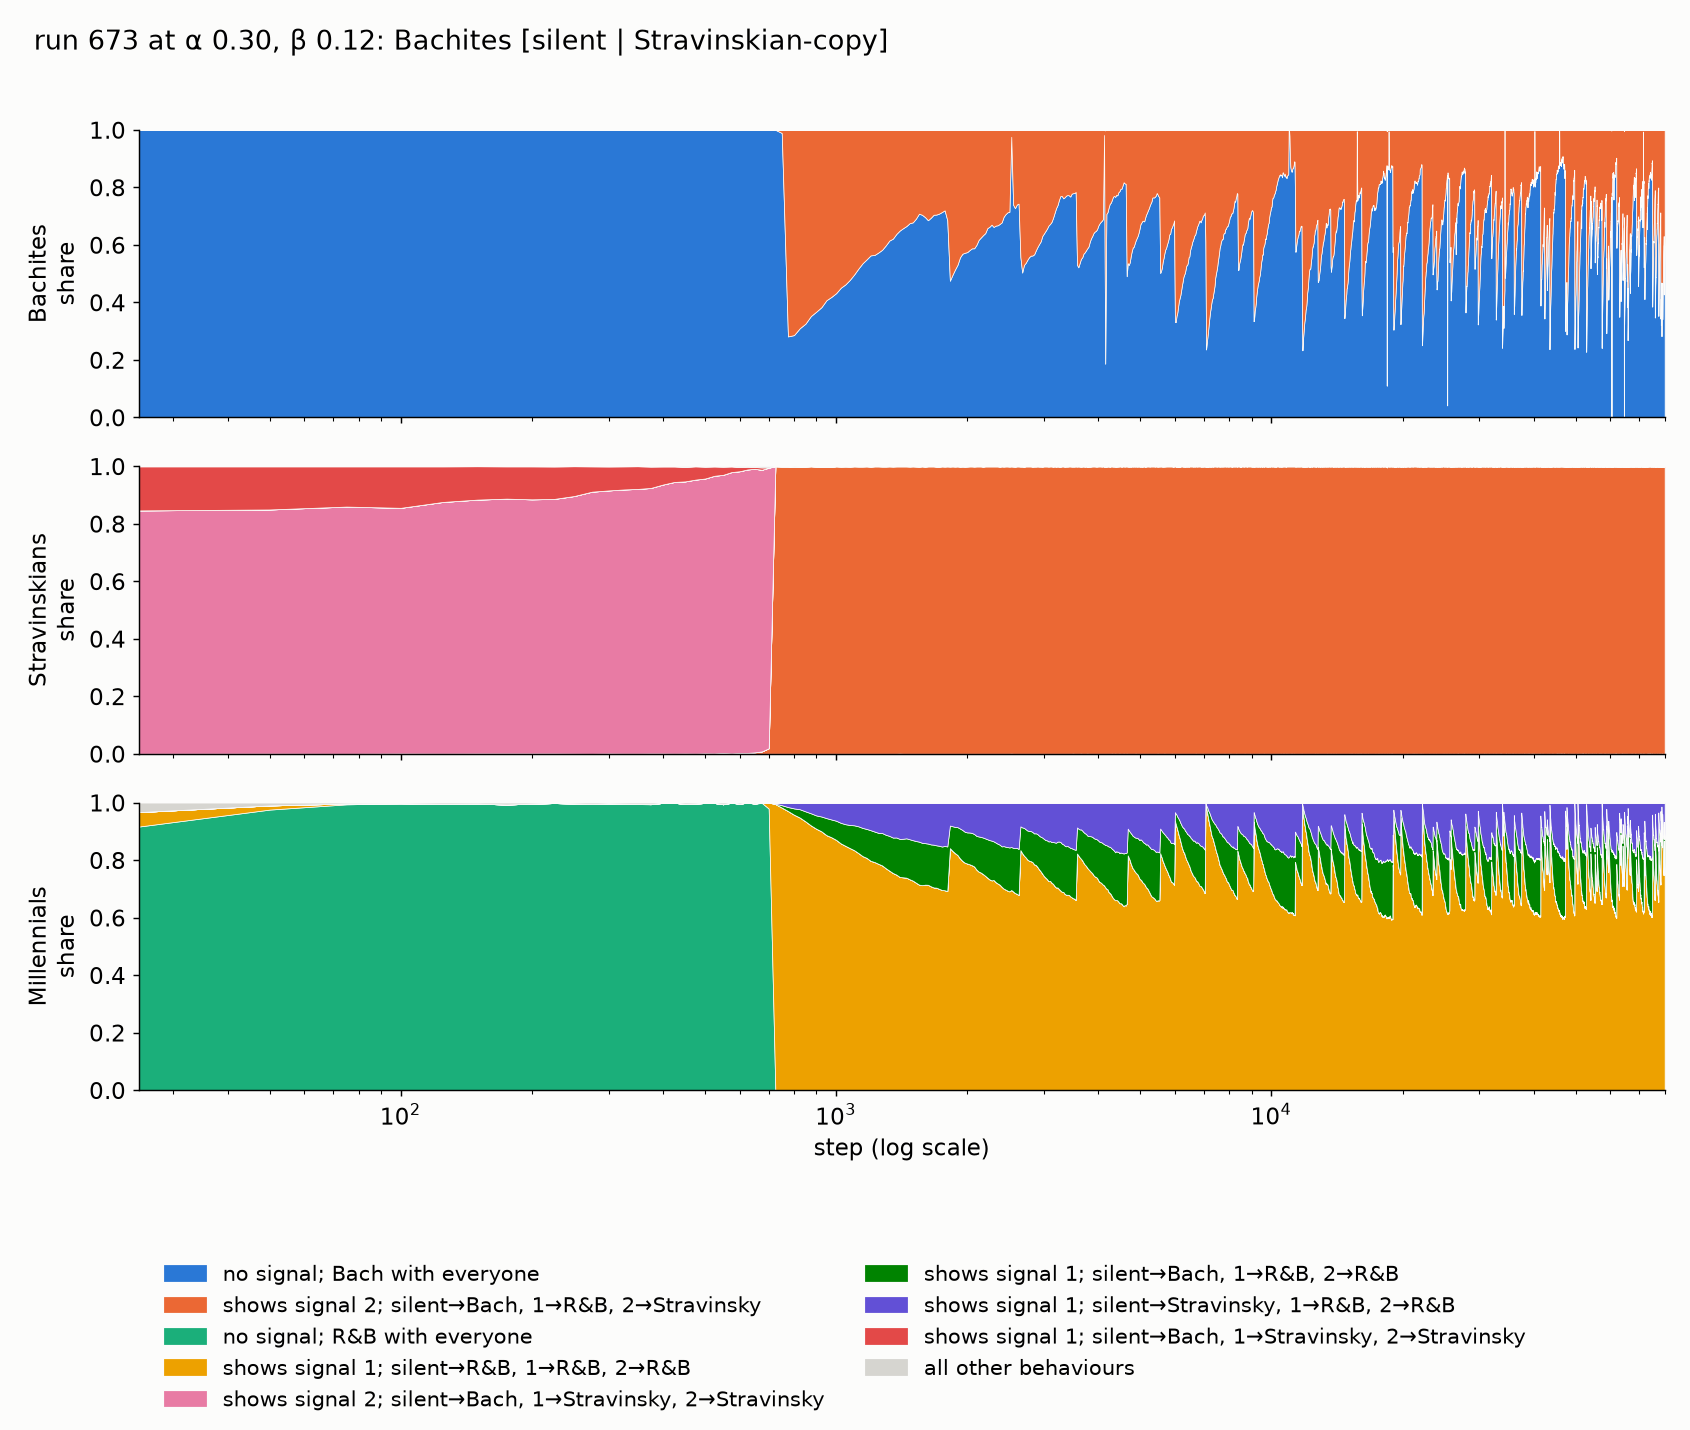

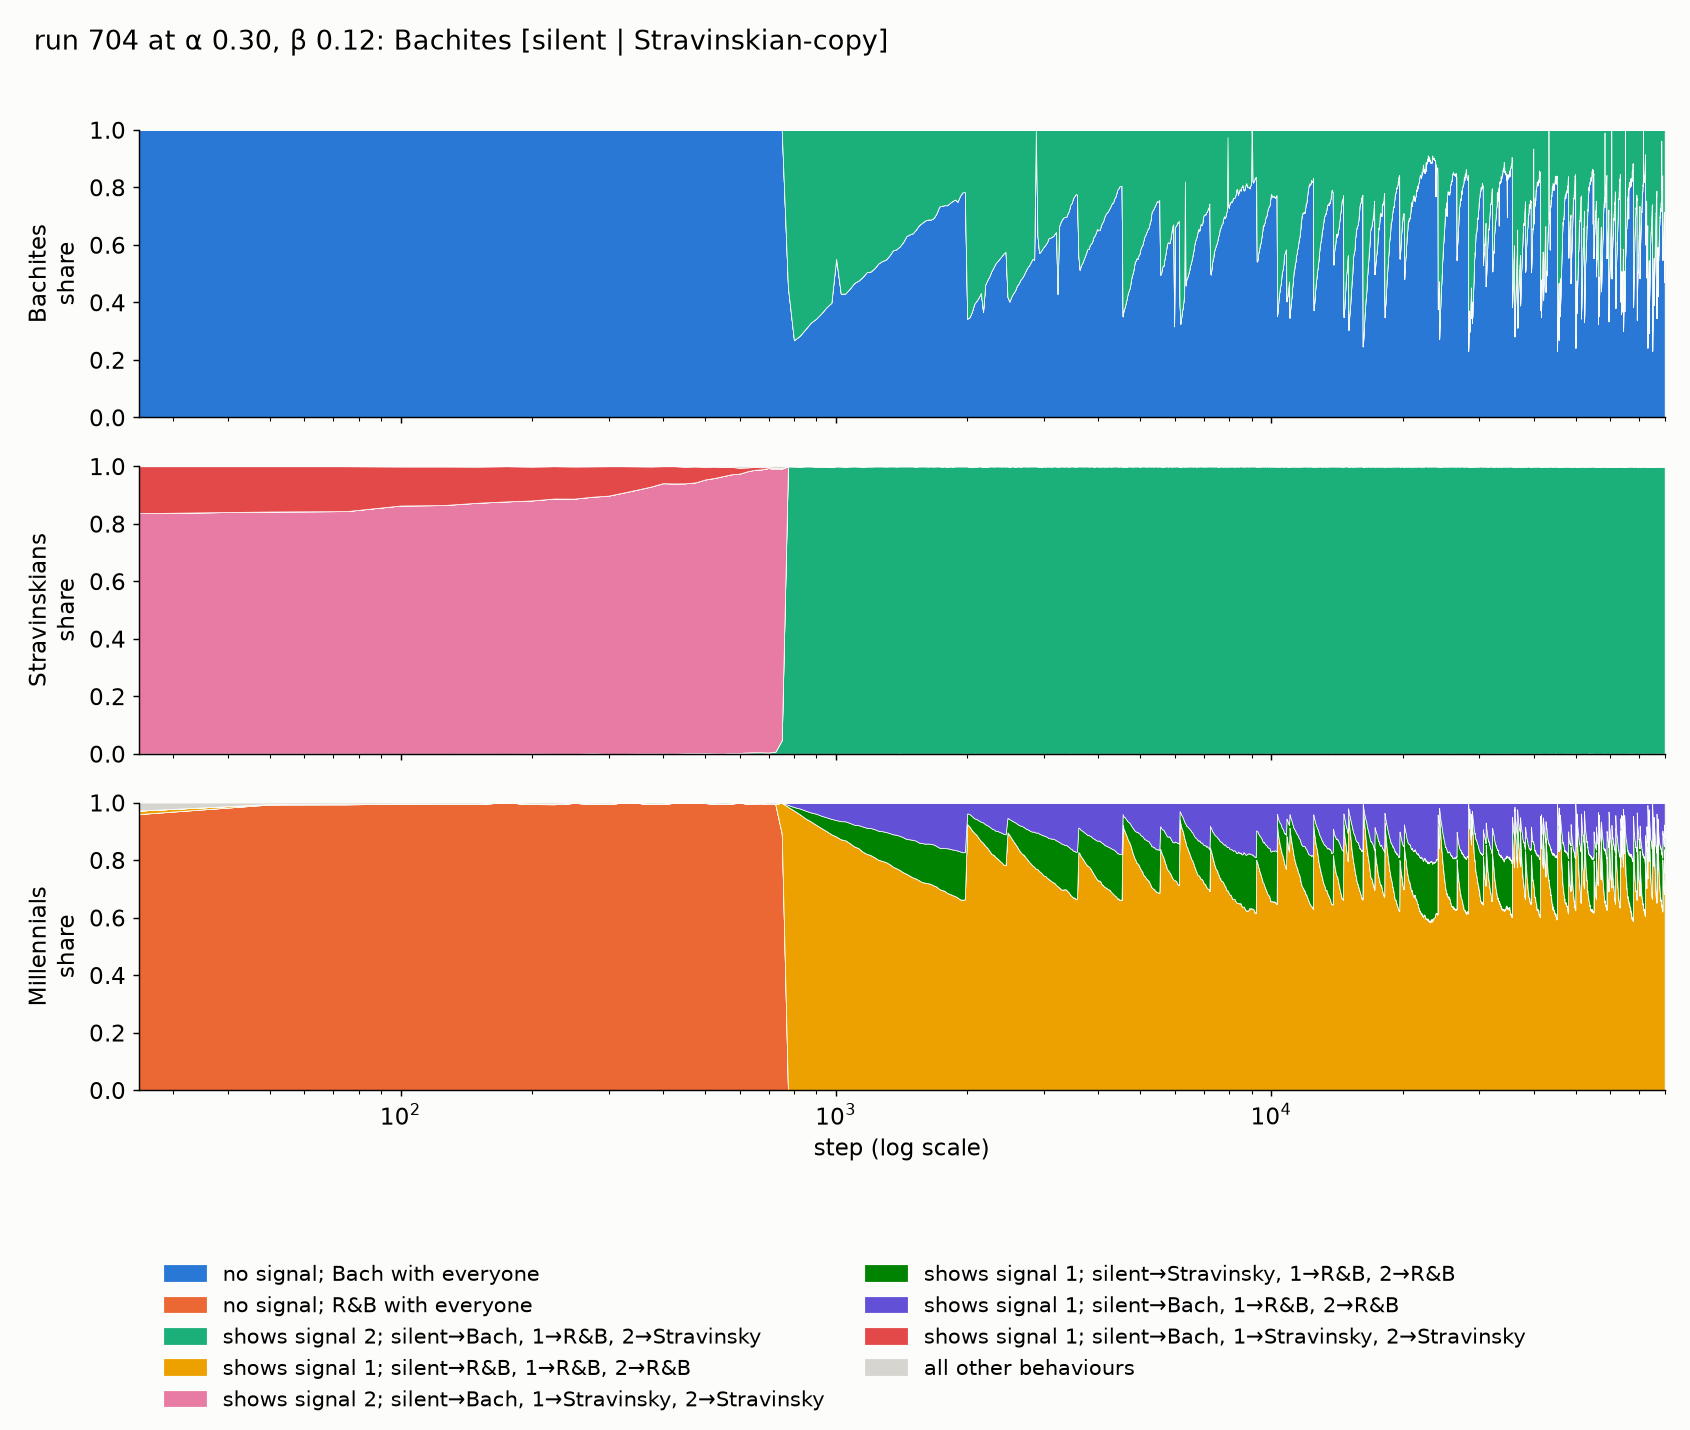

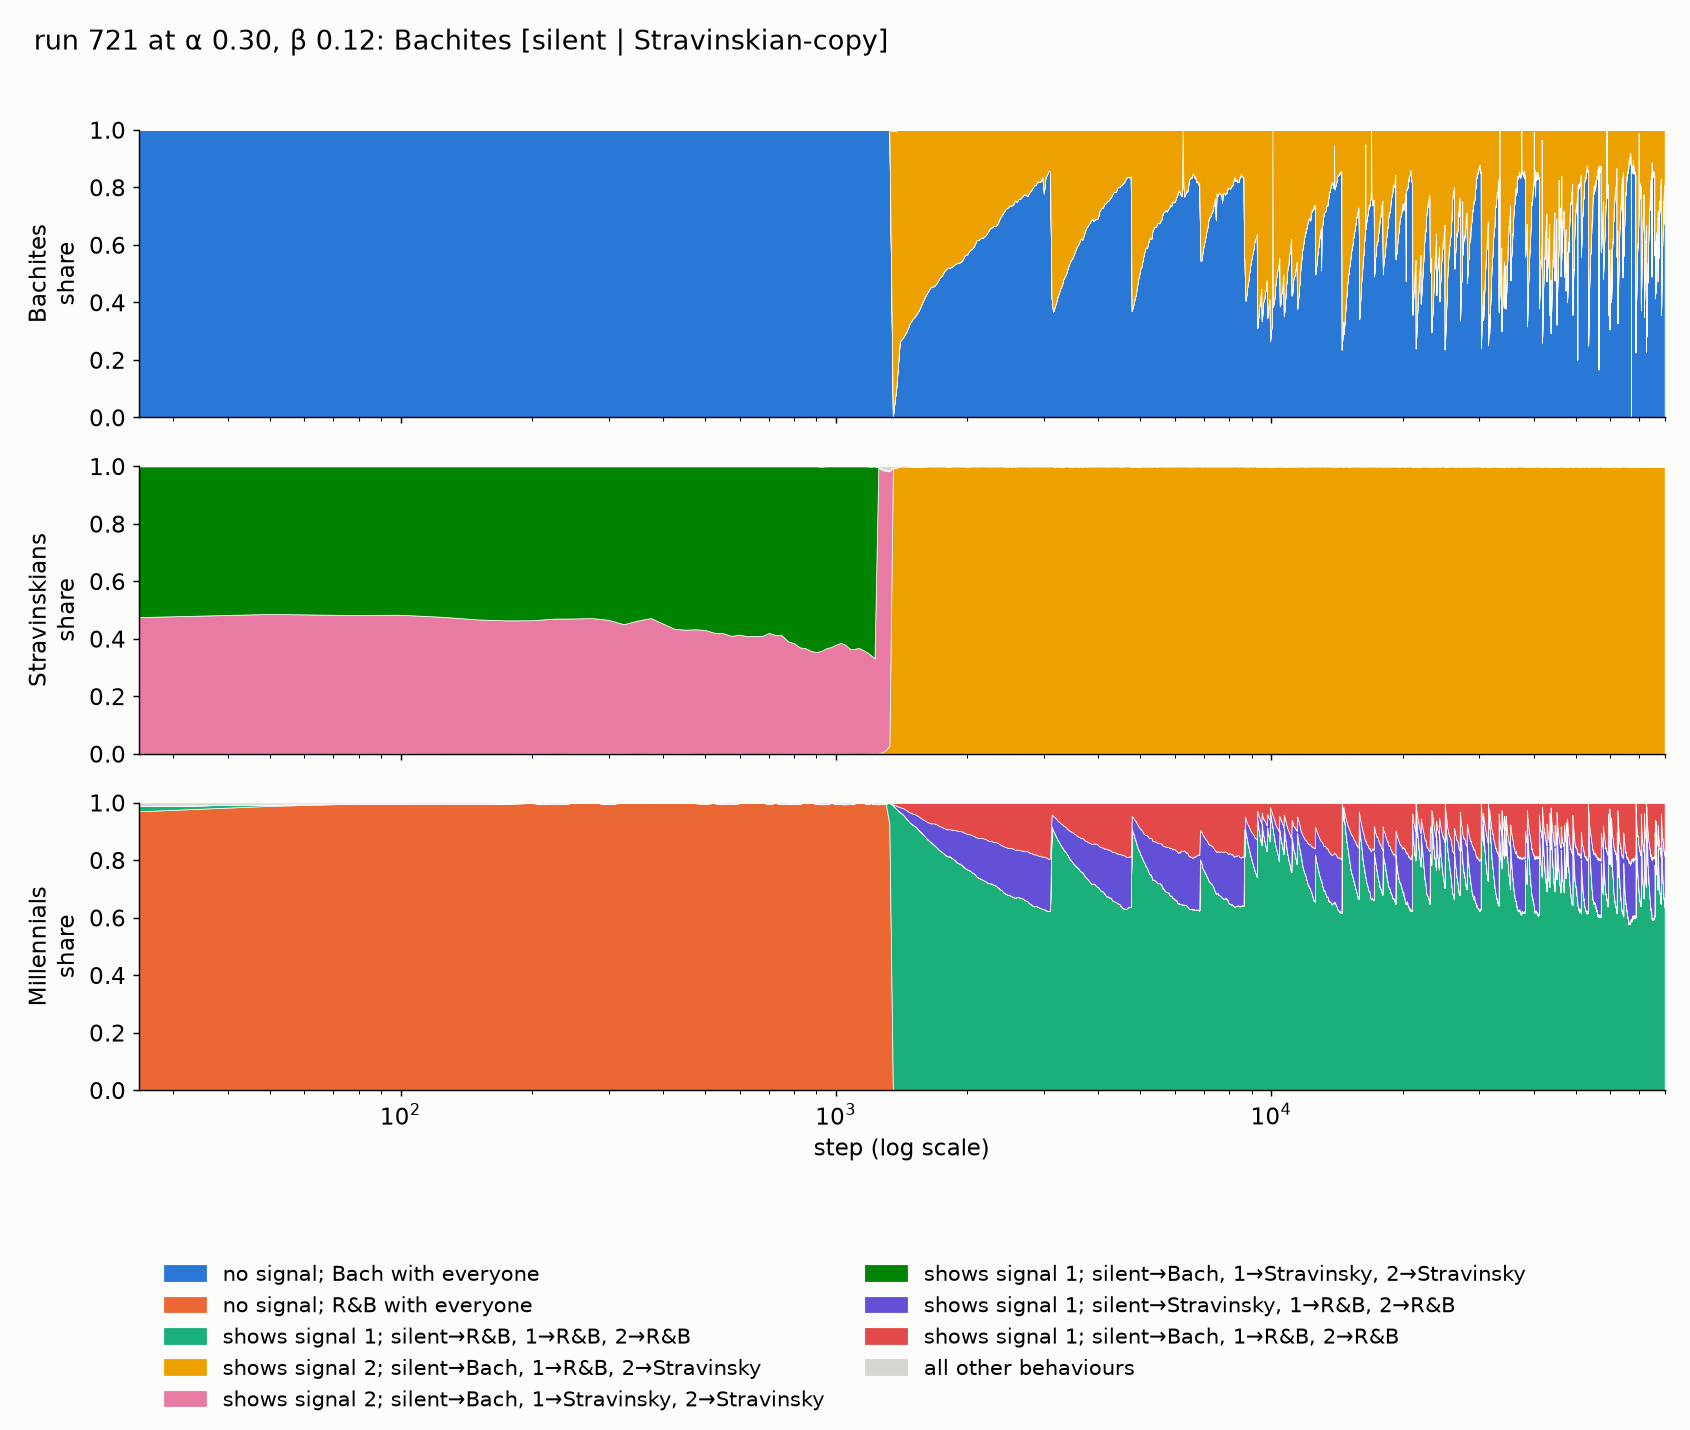

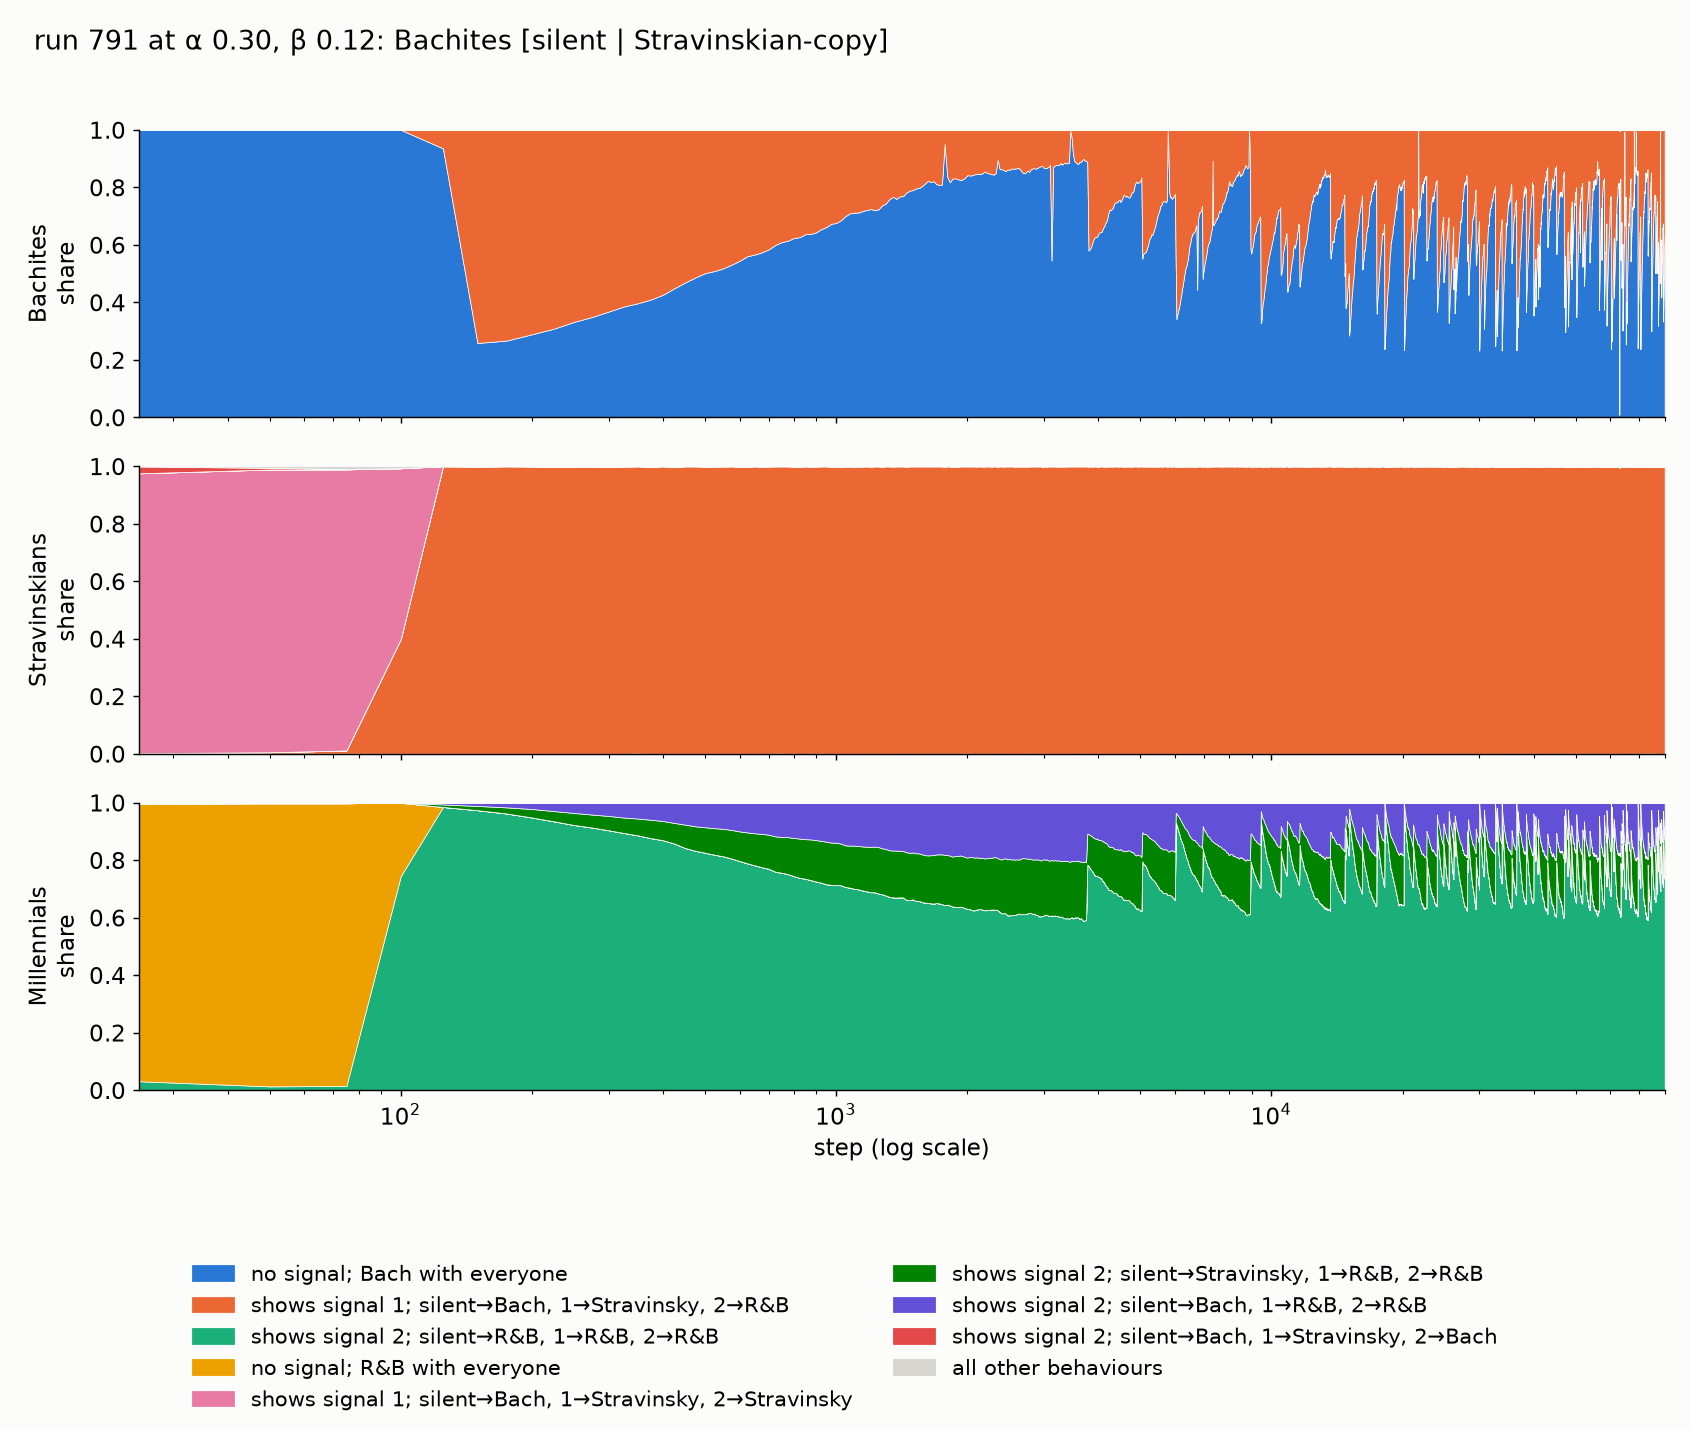

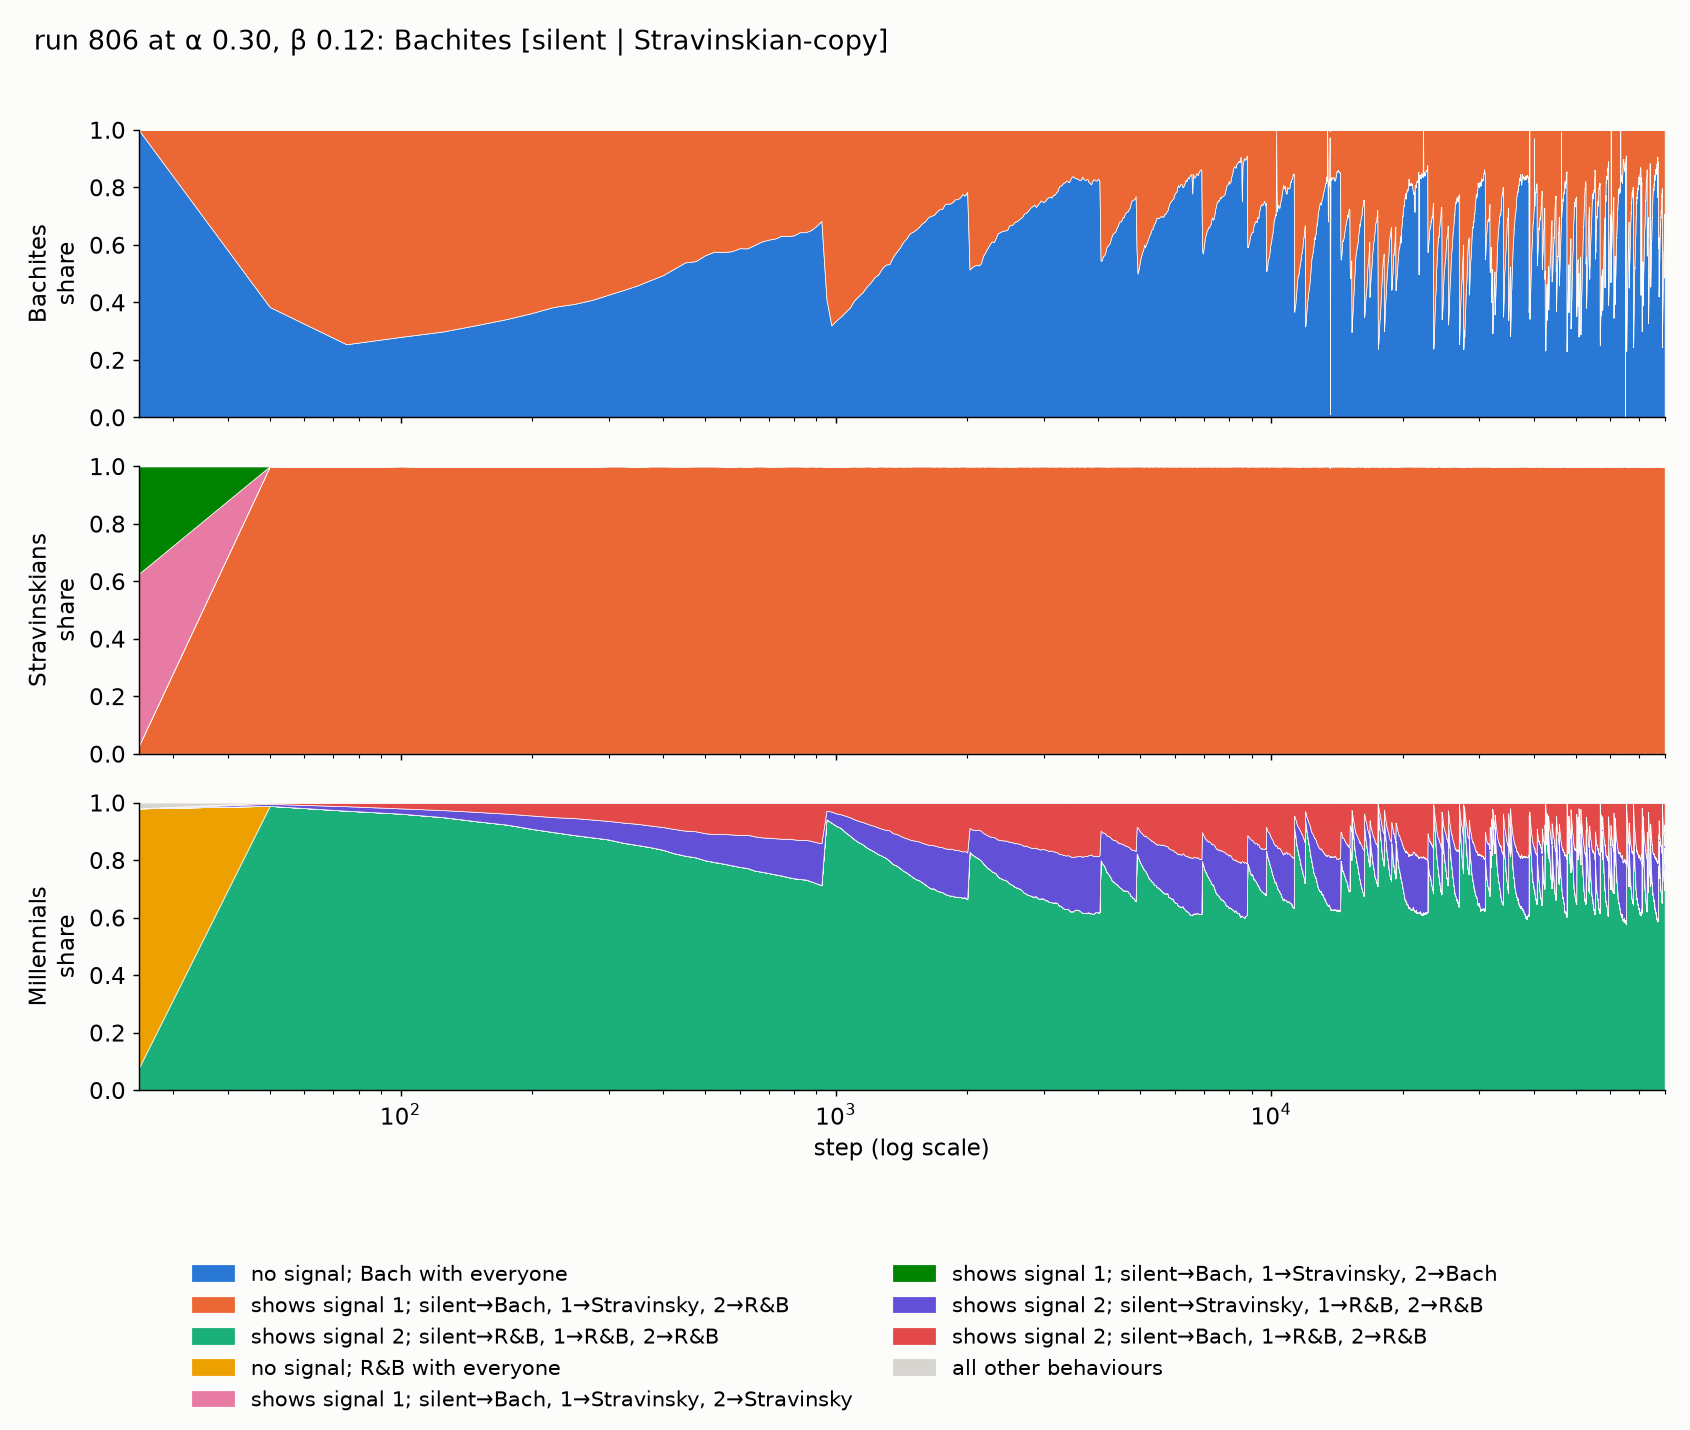

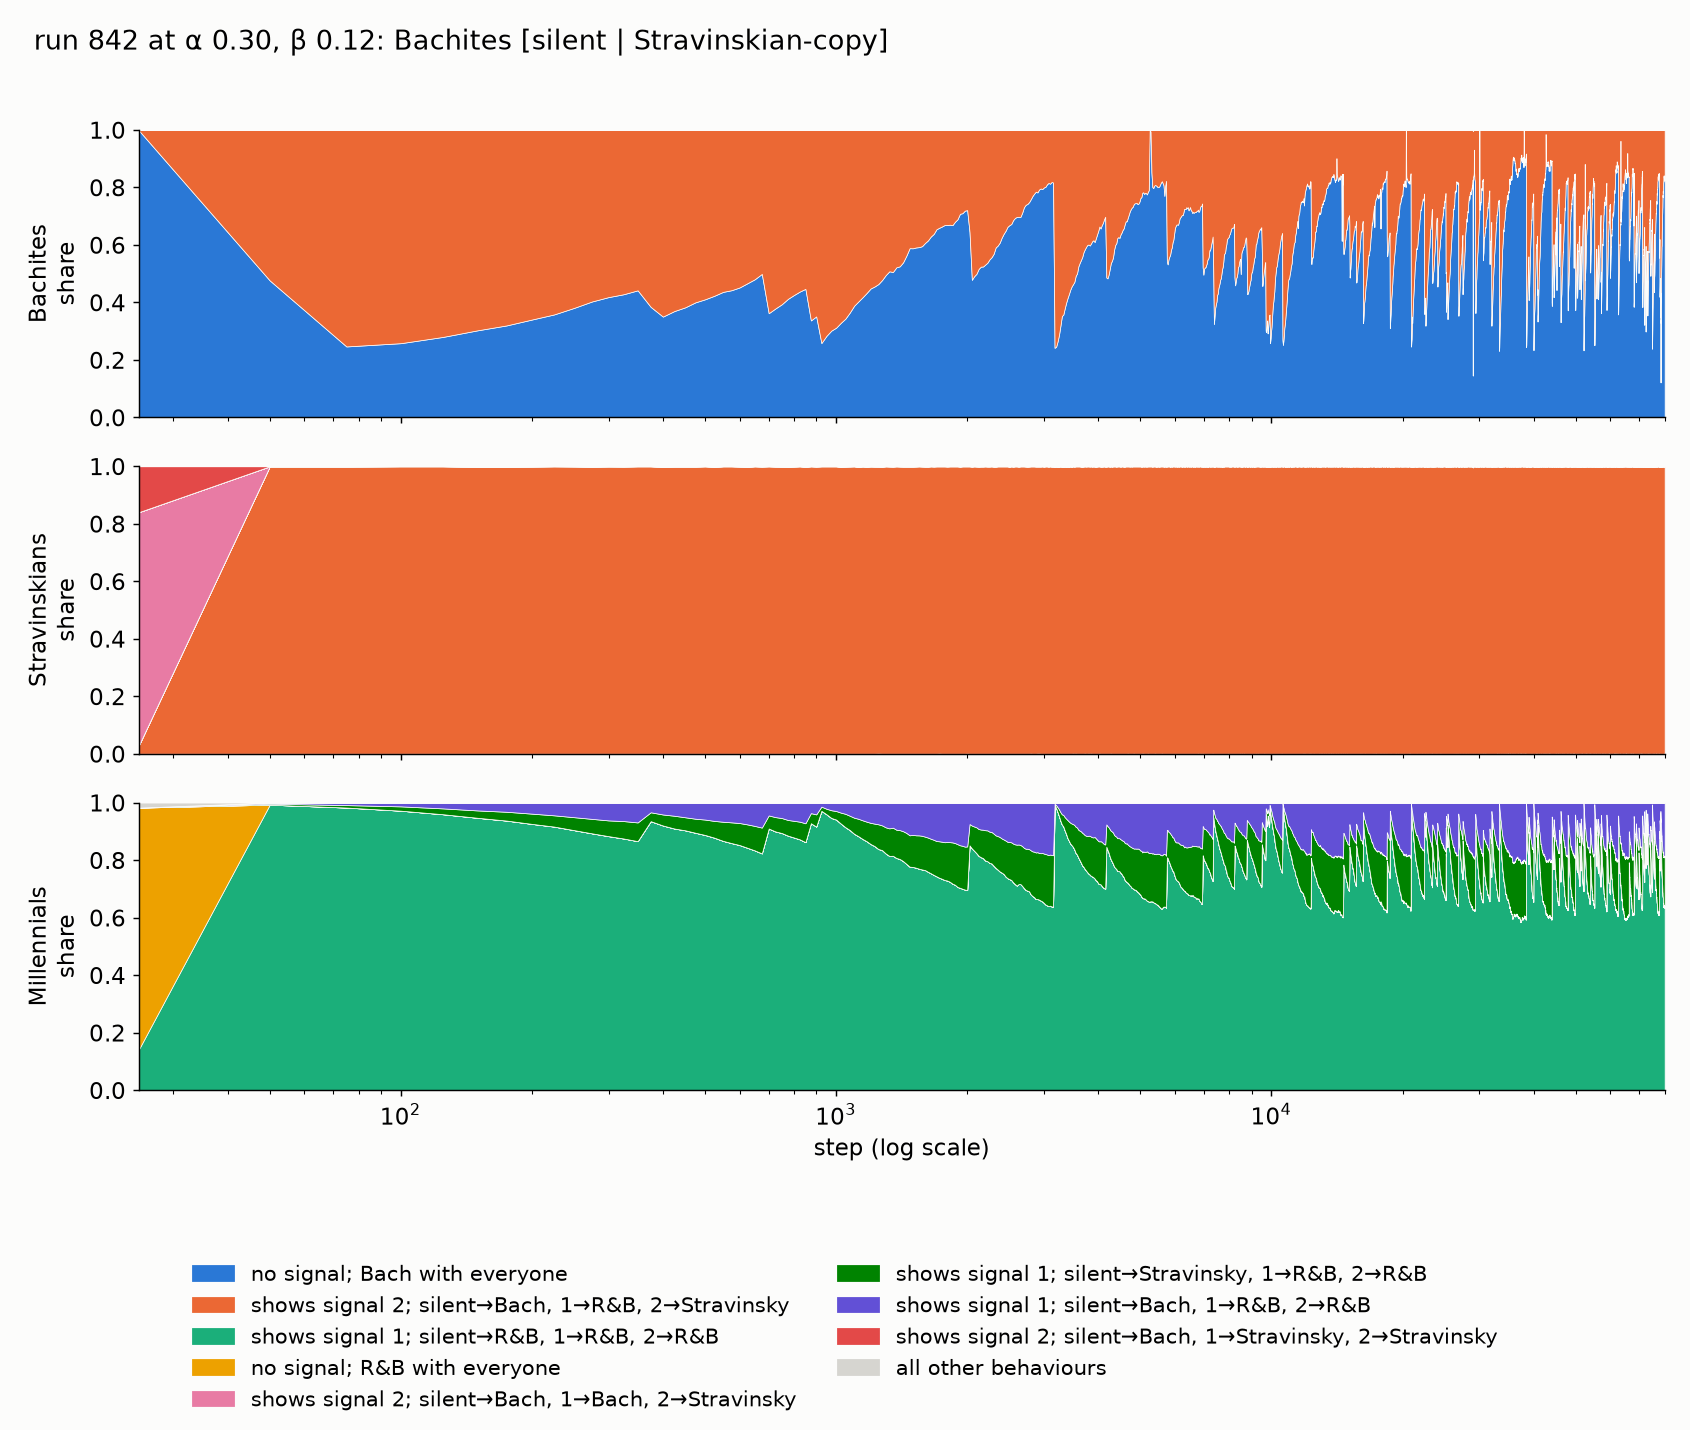

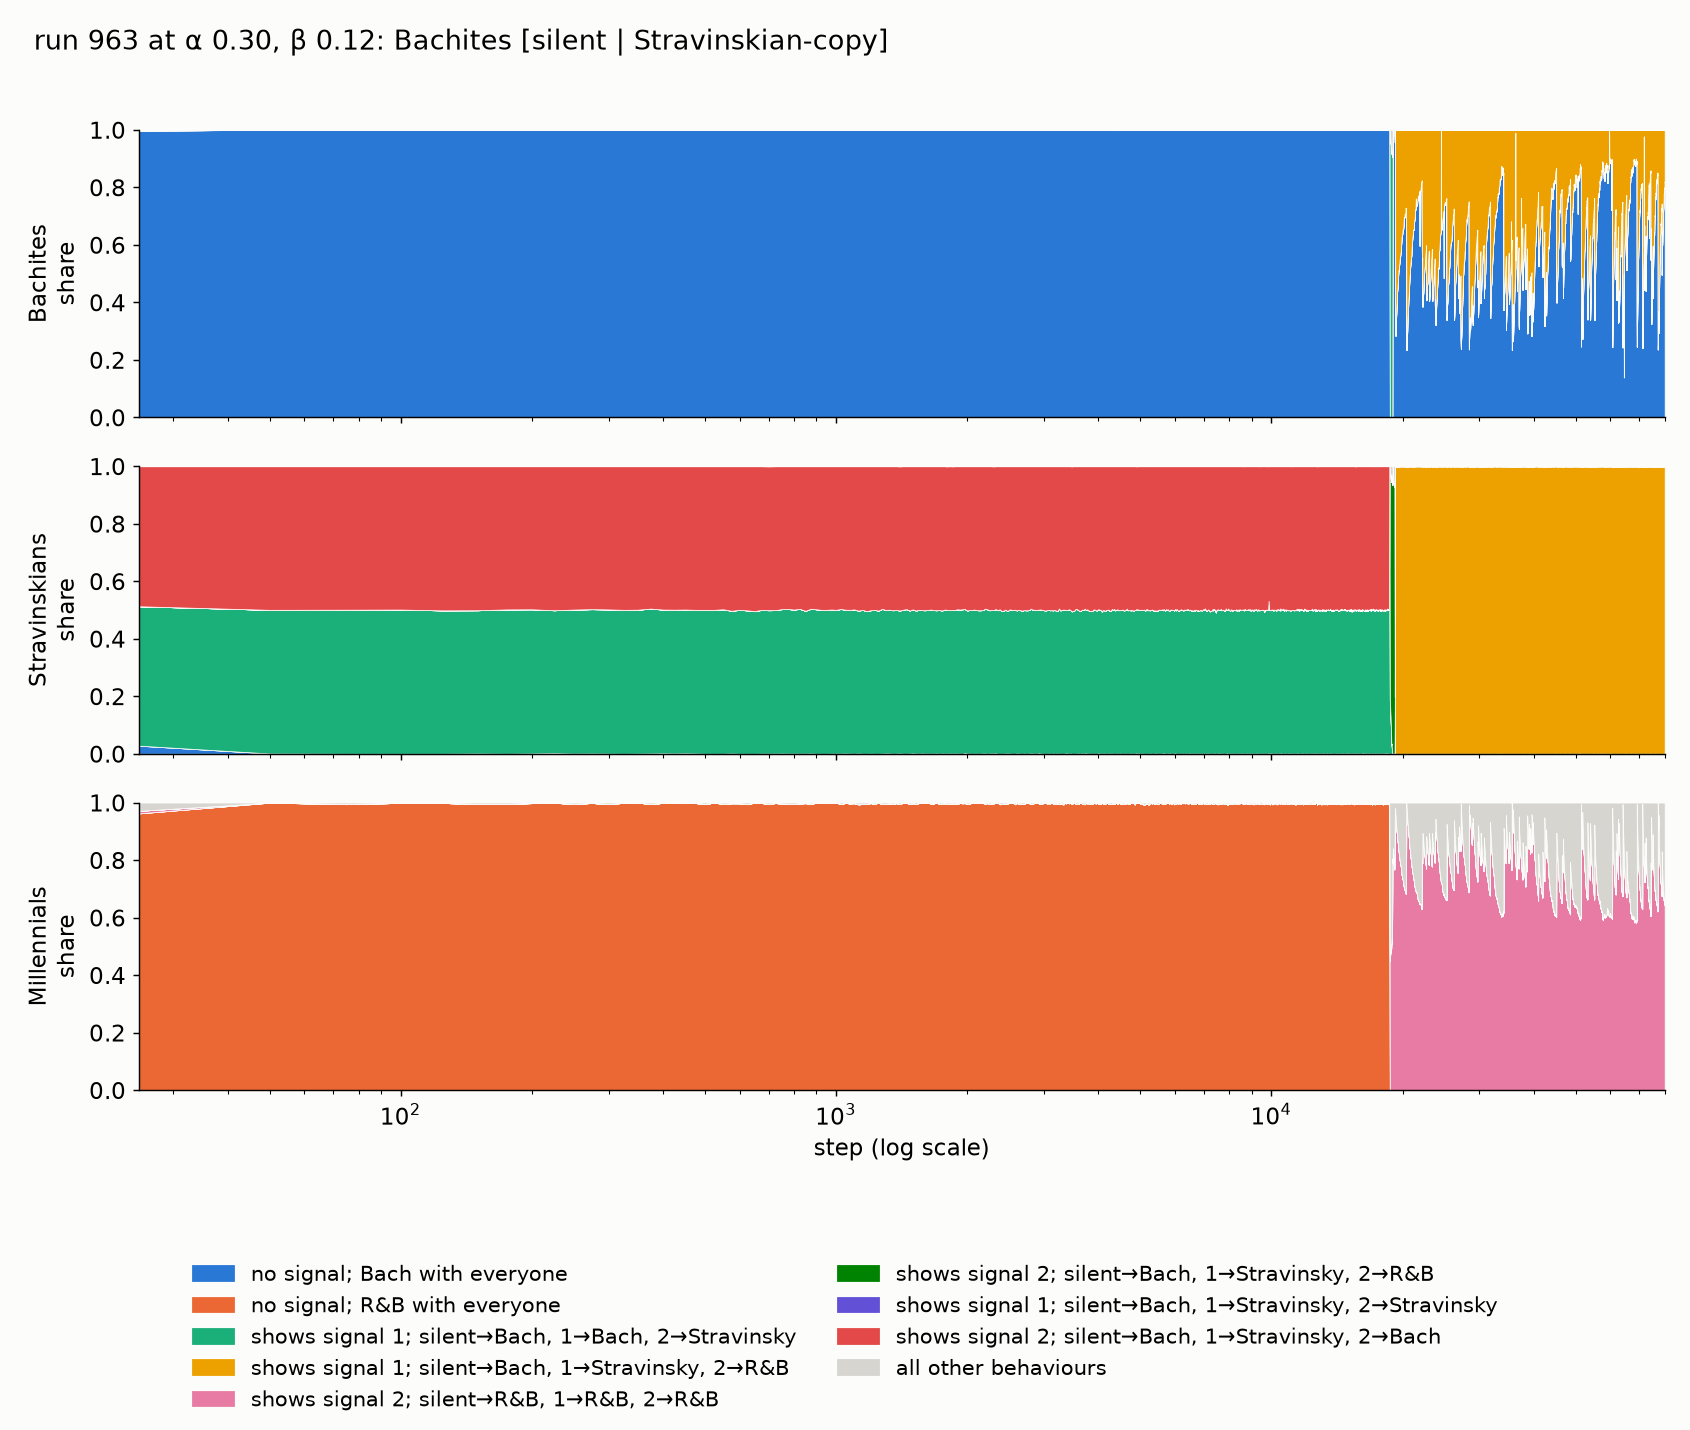

In [12]:
from IPython.display import Image, display
for k, rs in CHOSEN.items():
    print(k)
    for r in rs:
        display(Image(f'{TFIG}/run{r:04d}.png', width=900))